# Previsão da demanda de ingressantes no ensino superior privado de São Paulo
### Projeto INEP – Censo da Educação Superior (2015–2024) · Análise exploratória e regressão linear

**Objetivo.** Estimar, com base no histórico do Censo da Educação Superior, quantos alunos ingressarão em cada curso e instituição no ano seguinte, de modo que as instituições possam dimensionar turmas, docentes e infraestrutura com antecedência.

**Estrutura: os cinco tipos de análise de dados.** O trabalho percorre, em ordem crescente de maturidade, as camadas da análise de dados:

| Camada | Pergunta que responde | Onde está neste documento |
|---|---|---|
| Descritiva | O que aconteceu? | Seção 2 |
| Diagnóstica | Por que aconteceu? | Seção 3 |
| Preditiva | O que deve acontecer? | Seções 4, 5 e 6 (presencial, EAD e teste de sensibilidade) |
| Prescritiva | O que fazer? | Seção 7 |
| Cognitiva | Como o sistema aprende e interage com o usuário? | Seção 8.5 (próximos passos) |

A seção 1 trata da preparação (conexão e carga dos dados) e a seção 8 reúne as conclusões e recomendações.

**Glossário rápido (termos usados ao longo do texto).**

| Termo | Significado |
|---|---|
| Ingressantes em vagas novas | Alunos que entraram no curso no ano pelo processo regular; é a variável que se deseja prever. |
| *t* e *t+1* | Ano de referência (*t*) e ano seguinte (*t+1*). O modelo usa informações de *t* para prever *t+1*. |
| Defasagem (*lag*) | Valor de uma variável em anos anteriores (por exemplo, ingressantes de *t−1*). |
| Linha de base (*baseline*) | Regra simples usada como régua mínima: "o ano que vem será igual a este ano". Um modelo só é útil se superar essa regra. |
| Validação temporal | O modelo é treinado apenas com o passado e testado em anos posteriores, como ocorreria na prática. |
| Holdout | Ano reservado (2024) que não participa de nenhuma escolha de modelo e serve de teste final. |
| MAE | Erro absoluto médio, em número de alunos. |
| WAPE | Erro percentual ponderado: soma dos erros dividida pela soma do valor real. Quanto menor, melhor (0,30 = erro de 30%). |
| Viés | Tendência do modelo de errar sempre para mais (positivo) ou para menos (negativo). |
| Cenário | Hipótese de crescimento (pessimista, base ou otimista) usada para apresentar a previsão como uma faixa. |

## 1. Preparação do ambiente e carga dos dados

**Bibliotecas.** A célula seguinte carrega as ferramentas utilizadas: `pandas` e `numpy` para manipular tabelas e cálculos, `matplotlib`, `seaborn` e `plotly` para gráficos, e `snowflake.connector` para consultar o banco de dados em que a base do INEP está armazenada. Nenhuma operação sobre os dados ocorre ainda nesta etapa.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import snowflake.connector
from dotenv import find_dotenv, load_dotenv
from IPython.display import display

plt.style.use('ggplot')
pd.set_option('display.max_columns', 40)

**Conexão com o banco de dados.** As credenciais de acesso ao Snowflake ficam em um arquivo de variáveis de ambiente (`.env`), fora do código, de modo que senhas não sejam expostas nem versionadas. A função `get_env` busca cada variável e interrompe a execução com uma mensagem clara caso alguma esteja ausente.

In [2]:
env_path = find_dotenv(usecwd=True)
load_dotenv(env_path, override=True)

def get_env(*names, required=True):
    for name in names:
        value = os.getenv(name)
        if value:
            return value
    if required:
        raise ValueError("Variavel de ambiente ausente: " + " ou ".join(names))
    return None

conn = snowflake.connector.connect(
    account=get_env("SF_ACCOUNT", "SNOWFLAKE_ACCOUNT"),
    user=get_env("SF_USER", "SNOWFLAKE_USER"),
    password=get_env("SF_PASSWORD", "SNOWFLAKE_PASSWORD"),
    warehouse=get_env("SF_WAREHOUSE", "SNOWFLAKE_WAREHOUSE"),
    database=get_env("SF_DATABASE", "SNOWFLAKE_DATABASE"),
    schema=get_env("SF_SCHEMA", "SNOWFLAKE_SCHEMA"),
    role=get_env("SF_ROLE", "SNOEFLAKE_ROLE", required=False)
)

print("Conectado ao Snowflake")

Conectado ao Snowflake


**Carga da base analítica.** A consulta lê a visão `VW_CURSOS_SP_PRIVADA_2015_2024_ML`, que reúne, para cada ano, instituição, curso e município, a quantidade de vagas, inscrições, ingressantes e concluintes das instituições **privadas do estado de São Paulo** (graduação). Os registros são ordenados por ano, instituição e curso e armazenados na tabela `df`.

In [3]:
query = """
SELECT *
FROM PROJETO_INEP.ANALYTICS.VW_CURSOS_SP_PRIVADA_2015_2024_ML
ORDER BY ANO_CENSO, COD_IES, COD_CURSO
"""
with conn.cursor() as cursor:
    cursor.execute(query)
    df = cursor.fetch_pandas_all()

print(f"Fonte carregada: {len(df):,} registros e {df.shape[1]} colunas")

Fonte carregada: 698,004 registros e 27 colunas


## 2. Análise descritiva: o que aconteceu?

**2.1 Estrutura da base.** Verificam-se o número de linhas e colunas, o tipo de cada variável e a divisão entre as modalidades Presencial e EAD. O objetivo é conhecer o tamanho da base e identificar, desde o início, se as duas modalidades têm o mesmo grau de detalhamento.

In [4]:
# Estrutura
print(df.shape)
print(df.dtypes)
print(df["MODALIDADE_ENSINO"].value_counts(dropna=False))

(698004, 27)
ANO_CENSO                         int16
COD_IES                           int16
NOME_IES                         object
SIGLA_IES                        object
ORGANIZACAO_ACADEMICA              int8
COD_REDE                           int8
COD_CURSO                         int32
NOME_CURSO                       object
COD_MUNICIPIO                     int32
NOME_MUNICIPIO_CURSO             object
SIGLA_UF_CURSO                   object
COD_CINE                         object
NOME_AREA_GERAL_CINE             object
MODALIDADE_ENSINO                object
GRAU_ACADEMICO                  float64
QTD_CURSOS                         int8
QTD_VAGAS_TOTAL                   int32
QTD_VAGAS_NOVAS                   int32
QTD_INSCRICOES_VAGAS_NOVAS        int32
QTD_INGRESSANTES_TOTAL            int16
QTD_INGRESSANTES_VAGAS_NOVAS      int16
QTD_INGRESSANTES_FEMININO         int16
QTD_INGRESSANTES_MASCULINO        int16
QTD_CONCLUINTES                   int16
QTD_FIES                   

**2.2 Valores ausentes.** Para cada coluna, calcula-se a quantidade e o percentual de valores nulos, no conjunto total e por modalidade. Valores ausentes podem distorcer médias e impedir o cálculo de alguns modelos, por isso precisam ser mapeados antes de qualquer previsão.

*Leitura esperada:* apenas `SIGLA_IES` (≈10%) e `GRAU_ACADEMICO` (≈0,1%) possuem nulos; as variáveis quantitativas estão completas.

In [5]:
# Nulos por coluna, total e por modalidade
nulos = df.isna().sum().to_frame("nulos")
nulos["%"] = (nulos["nulos"] / len(df) * 100).round(2)
print(nulos.sort_values("nulos", ascending=False))
print(df.groupby("MODALIDADE_ENSINO").apply(lambda g: g.isna().mean().round(3)).T)

                              nulos      %
SIGLA_IES                     72928  10.45
GRAU_ACADEMICO                  819   0.12
COD_IES                           0   0.00
NOME_IES                          0   0.00
ORGANIZACAO_ACADEMICA             0   0.00
COD_REDE                          0   0.00
COD_CURSO                         0   0.00
NOME_CURSO                        0   0.00
COD_MUNICIPIO                     0   0.00
NOME_MUNICIPIO_CURSO              0   0.00
ANO_CENSO                         0   0.00
SIGLA_UF_CURSO                    0   0.00
COD_CINE                          0   0.00
NOME_AREA_GERAL_CINE              0   0.00
MODALIDADE_ENSINO                 0   0.00
QTD_CURSOS                        0   0.00
QTD_VAGAS_TOTAL                   0   0.00
QTD_VAGAS_NOVAS                   0   0.00
QTD_INSCRICOES_VAGAS_NOVAS        0   0.00
QTD_INGRESSANTES_TOTAL            0   0.00
QTD_INGRESSANTES_VAGAS_NOVAS      0   0.00
QTD_INGRESSANTES_FEMININO         0   0.00
QTD_INGRESS

MODALIDADE_ENSINO               EAD  Presencial
ANO_CENSO                     0.000       0.000
COD_IES                       0.000       0.000
NOME_IES                      0.000       0.000
SIGLA_IES                     0.103       0.120
ORGANIZACAO_ACADEMICA         0.000       0.000
COD_REDE                      0.000       0.000
COD_CURSO                     0.000       0.000
NOME_CURSO                    0.000       0.000
COD_MUNICIPIO                 0.000       0.000
NOME_MUNICIPIO_CURSO          0.000       0.000
SIGLA_UF_CURSO                0.000       0.000
COD_CINE                      0.000       0.000
NOME_AREA_GERAL_CINE          0.000       0.000
MODALIDADE_ENSINO             0.000       0.000
GRAU_ACADEMICO                0.001       0.002
QTD_CURSOS                    0.000       0.000
QTD_VAGAS_TOTAL               0.000       0.000
QTD_VAGAS_NOVAS               0.000       0.000
QTD_INSCRICOES_VAGAS_NOVAS    0.000       0.000
QTD_INGRESSANTES_TOTAL        0.000     

C:\Users\jan.eduardo\AppData\Local\Temp\ipykernel_23836\2583110952.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df.groupby("MODALIDADE_ENSINO").apply(lambda g: g.isna().mean().round(3)).T)


**2.3 Zeros em variáveis quantitativas.** Em dados de contagem, o zero pode significar "nenhum aluno" (informação legítima) ou "dado não informado" (ausência disfarçada). A tabela mostra a proporção de zeros em cada coluna, no total e por modalidade.

*Leitura esperada:* no EAD, as colunas de **vagas, inscrições e quantidade de cursos são 100% zero**. Isso indica que o Censo não registra essas informações para a modalidade EAD, o que condiciona toda a modelagem posterior.

In [6]:
# Zeros suspeitos nas colunas de quantidade
qtd = [c for c in df.columns if c.startswith("QTD")]
print((df[qtd] == 0).mean().round(3).sort_values(ascending=False))
print(df.groupby("MODALIDADE_ENSINO")[qtd].apply(lambda g: (g == 0).mean().round(3)).T)

QTD_FIES                        0.969
QTD_INSCRICOES_VAGAS_NOVAS      0.911
QTD_VAGAS_NOVAS                 0.907
QTD_VAGAS_TOTAL                 0.906
QTD_PROUNI                      0.904
QTD_CURSOS                      0.901
QTD_CONCLUINTES                 0.703
QTD_FINANCIAMENTO               0.674
QTD_INGRESSANTES_MASCULINO      0.424
QTD_INGRESSANTES_FEMININO       0.405
QTD_INGRESSANTES_VAGAS_NOVAS    0.255
QTD_INGRESSANTES_TOTAL          0.211
dtype: float64
MODALIDADE_ENSINO               EAD  Presencial
QTD_CURSOS                    1.000       0.002
QTD_VAGAS_TOTAL               1.000       0.046
QTD_VAGAS_NOVAS               1.000       0.060
QTD_INSCRICOES_VAGAS_NOVAS    1.000       0.100
QTD_INGRESSANTES_TOTAL        0.219       0.135
QTD_INGRESSANTES_VAGAS_NOVAS  0.265       0.161
QTD_INGRESSANTES_FEMININO     0.430       0.177
QTD_INGRESSANTES_MASCULINO    0.452       0.172
QTD_CONCLUINTES               0.756       0.226
QTD_FIES                      0.999       0.697
Q

**2.4 Evolução dos zeros ao longo do tempo.** A coluna `QTD_FIES` (financiamento estudantil) é examinada por ano e modalidade para verificar se a quantidade de zeros muda com o tempo. Aumentos graduais refletem mudanças reais na política de financiamento, e não erro de coleta.

In [7]:
# Zeros por ano e modalidade em uma coluna
print(df.assign(z=df["QTD_FIES"] == 0).pivot_table(index="ANO_CENSO", columns="MODALIDADE_ENSINO", values="z", aggfunc="mean").round(3))

MODALIDADE_ENSINO    EAD  Presencial
ANO_CENSO                           
2015               0.999       0.409
2016               0.981       0.451
2017               1.000       0.464
2018               0.999       0.649
2019               1.000       0.739
2020               0.999       0.814
2021               0.999       0.850
2022               1.000       0.881
2023               1.000       0.828
2024               1.000       0.891


**2.5 Chave de identificação e valores impossíveis.** Confirma-se que cada combinação de *ano × instituição × curso × município × modalidade* aparece uma única vez (ausência de duplicatas) e que nenhuma quantidade é negativa. Essa chave permite acompanhar o mesmo curso ao longo dos anos, condição necessária para construir o histórico usado na previsão.

In [8]:
# Granulidade e valores impossiveis
keys = ["ANO_CENSO", "COD_IES", "COD_CURSO", "COD_MUNICIPIO", "MODALIDADE_ENSINO"]
print("dup na chave:", df.duplicated(keys).sum())
print("negativos:", (df[qtd] < 0).sum()[lambda s: s > 0])
print(df[qtd].describe().T)

dup na chave: 0
negativos: Series([], dtype: int64)


                                 count       mean         std  min  25%  50%  \
QTD_CURSOS                    698004.0   0.098634    0.298170  0.0  0.0  0.0   
QTD_VAGAS_TOTAL               698004.0  22.268531  107.747696  0.0  0.0  0.0   
QTD_VAGAS_NOVAS               698004.0  16.075560   72.965197  0.0  0.0  0.0   
QTD_INSCRICOES_VAGAS_NOVAS    698004.0  25.548616  184.235614  0.0  0.0  0.0   
QTD_INGRESSANTES_TOTAL        698004.0  13.075434   55.970305  0.0  1.0  2.0   
QTD_INGRESSANTES_VAGAS_NOVAS  698004.0  11.311852   46.466696  0.0  0.0  1.0   
QTD_INGRESSANTES_FEMININO     698004.0   7.647013   40.325149  0.0  0.0  1.0   
QTD_INGRESSANTES_MASCULINO    698004.0   5.428420   22.636520  0.0  0.0  1.0   
QTD_CONCLUINTES               698004.0   4.229002   22.847171  0.0  0.0  0.0   
QTD_FIES                      698004.0   0.249175    3.210452  0.0  0.0  0.0   
QTD_PROUNI                    698004.0   0.524484    3.493064  0.0  0.0  0.0   
QTD_FINANCIAMENTO             698004.0  

**2.6 Carga dos dados do EAD diretamente da camada confiável (TRUSTED).** Para detalhar a modalidade EAD, que é o foco da instituição, e como matrículas e evasão não constam na visão analítica, a consulta é feita na tabela `TB_CURSOS`, filtrando: modalidade EAD, estado de São Paulo, rede privada e nível de graduação. Valores nulos são tratados como zero para as quantidades, e os nomes das colunas são abreviados para facilitar a leitura do código (`ING` = ingressantes, `ING_NOVA` = ingressantes em vagas novas, `MAT` = matrículas, `CONC` = concluintes, `DESV` = desvinculados, `TRANC` = trancados).

In [9]:
query_ead = """
SELECT NU_ANO_CENSO AS ANO, CO_IES, CO_CURSO, CO_MUNICIPIO,
       NO_CINE_AREA_GERAL AS AREA, TP_ORGANIZACAO_ACADEMICA AS ORG,
       COALESCE(QT_ING, 0)           AS ING,
       COALESCE(QT_ING_VG_NOVA, 0)   AS ING_NOVA,
       COALESCE(QT_MAT, 0)           AS MAT,
       COALESCE(QT_CONC, 0)          AS CONC,
       COALESCE(QT_ING_FINANC, 0)    AS FIN,
       COALESCE(QT_SIT_DESVINCULADO, 0) AS DESV,
       COALESCE(QT_SIT_TRANCADA, 0)  AS TRANC
FROM PROJETO_INEP.TRUSTED.TB_CURSOS
WHERE TP_MODALIDADE_ENSINO = 2   -- EAD
  AND SG_UF = 'SP'
  AND TP_REDE = 2                -- privada
  AND TP_NIVEL_ACADEMICO = 1     -- graduação
"""
with conn.cursor() as cursor:
    cursor.execute(query_ead)
    ead = cursor.fetch_pandas_all()
ead.columns = [c.upper() for c in ead.columns]
print(f"EAD carregado: {len(ead):,} registros")

EAD carregado: 629,044 registros


**2.7 Verificação da disponibilidade de vagas e inscrições no EAD.** Soma-se, por ano, o que o Censo registra de vagas e inscrições para o EAD, em comparação com ingressantes e matrículas. Valores nulos (2015–2019) ou zerados (2020–2024) confirmam que a ausência de vagas é uma característica da fonte, e não um erro de carga.

In [10]:
q_disp = """
SELECT NU_ANO_CENSO AS ANO,
       SUM(QT_VG_TOTAL)        AS VAGAS_TOTAL,
       SUM(QT_VG_TOTAL_EAD)    AS VAGAS_EAD,
       SUM(QT_INSCRITO_TOTAL)  AS INSCRICOES,
       SUM(QT_ING_VG_NOVA)     AS INGRESSANTES_VAGAS_NOVAS,
       SUM(QT_MAT)             AS MATRICULAS
FROM PROJETO_INEP.TRUSTED.TB_CURSOS
WHERE TP_MODALIDADE_ENSINO = 2 AND SG_UF = 'SP' AND TP_REDE = 2 AND TP_NIVEL_ACADEMICO = 1
GROUP BY 1 ORDER BY 1
"""
with conn.cursor() as cursor:
    cursor.execute(q_disp)
    disp = pd.DataFrame(cursor.fetchall(), columns=[c[0] for c in cursor.description])
display(disp)

,ANO,VAGAS_TOTAL,VAGAS_EAD,INSCRICOES,INGRESSANTES_VAGAS_NOVAS,MATRICULAS
0,2015,NaN,NaN,NaN,125916,257540
1,2016,NaN,NaN,NaN,172780,283082
2,2017,NaN,NaN,NaN,197304,320401
3,2018,NaN,NaN,NaN,237971,375411
4,2019,NaN,NaN,NaN,276492,445017
5,2020,0.0,0.0,0.0,379516,596312
6,2021,0.0,0.0,0.0,498415,744282
7,2022,0.0,0.0,0.0,604754,891550
8,2023,0.0,0.0,0.0,686837,1053426
9,2024,0.0,0.0,0.0,738784,1186645


## 3. Análise diagnóstica: por que aconteceu?

A análise descritiva mostrou *o que* ocorreu (o presencial encolheu e o EAD cresceu muito). Esta seção investiga o *porquê* e, principalmente, **onde o erro de previsão se concentra e por que**. Os resultados orientam as decisões de modelagem das seções seguintes.

Três perguntas são respondidas:

1. **De onde vem a variação anual dos ingressantes?** Do crescimento de cursos existentes, da queda de cursos existentes, do encerramento de cursos ou da entrada de cursos novos?
2. **Onde o modelo erra mais?** Em cursos grandes ou pequenos, em quais áreas, e nos cursos que acabam encerrados?
3. **Por que os modelos mais sofisticados (em escala logarítmica) pioraram a previsão?**

**3.1 Construção dos painéis (presencial e EAD).** As análises diagnóstica, preditiva e prescritiva usam a mesma estrutura de dados, chamada aqui de *painel*: para cada curso (ou instituição) e cada ano *t*, reúnem-se os ingressantes em vagas novas de *t* (`y0`), de *t−1* (`y1`) e de *t−2* (`y2`), as matrículas, os concluintes e a evasão, além do valor do ano seguinte (o alvo, `y_nextB`). Quando a combinação deixa de existir em *t+1*, o alvo é zero (encerramento).

O ensino presencial é convertido para o mesmo formato do EAD, o que permite aplicar exatamente as mesmas funções às duas modalidades. A função `look` localiza o valor de um ano diferente para a mesma entidade, sem usar informação futura nas variáveis explicativas. O ano de 2024 só aparece como alvo (teste final).

In [11]:
import warnings
from sklearn.linear_model import LinearRegression
warnings.filterwarnings("ignore")


def painel_ead(base, keys):
    """Monta o painel (variáveis em t, alvo em t+1) agregando `base` pelas colunas `keys`."""
    a = base.groupby(["ANO"] + keys, as_index=False).agg(
        y0=("ING_NOVA", "sum"), ing0=("ING", "sum"), mat0=("MAT", "sum"), conc0=("CONC", "sum"),
        fin0=("FIN", "sum"), saida0=("DESV", "sum"), npolos=("CO_MUNICIPIO", "nunique"))
    a = a.rename(columns={"ANO": "T"})
    lk = a.set_index(keys + ["T"])

    def look(col, lag):
        """Valor de `col` em t-lag (lag>0) ou t+|lag| (lag<0) para a mesma chave; NaN se não existir."""
        idx = pd.MultiIndex.from_frame(a[keys].assign(T=a["T"] - lag))
        return lk[col].reindex(idx).to_numpy()

    a["y1"], a["y2"], a["mat1"] = look("y0", 1), look("y0", 2), look("mat0", 1)
    a["TEM1"], a["TEM2"] = a["y1"].notna().astype(int), a["y2"].notna().astype(int)
    for c in ["y1", "y2", "mat1"]:
        a[c] = a[c].fillna(0)
    a["y_next"] = look("y0", -1)                 # NaN: a combinação não existe em t+1
    a["y_nextB"] = a["y_next"].fillna(0)         # cenário B: encerramento = 0 ingressantes
    a["FECHOU"] = a["y_next"].isna().astype(int)
    a["ma3"] = (a.y0 + a.y1 + a.y2) / (1 + a.TEM1 + a.TEM2)
    a["MATg"] = ((a.mat0 - a.mat1) / a.mat1.replace(0, np.nan)).clip(-1, 5).fillna(0)
    a["ING_MAT"] = (a.ing0 / a.mat0.replace(0, np.nan)).clip(0, 5).fillna(0)
    a["NOVO"] = (a.TEM1 == 0).astype(int)        # curso sem histórico em t-1
    a["y0_novo"], a["y0_velho"] = a.y0 * a.NOVO, a.y0 * (1 - a.NOVO)
    return a[a["T"] <= 2023].copy()               # 2023 -> alvo 2024 (teste final)


F_EAD = ["y0", "y1", "y2", "ma3", "mat0", "mat1", "conc0", "ing0", "fin0", "saida0", "npolos", "TEM1", "TEM2", "MATg", "ING_MAT"]
area_curso = ead.drop_duplicates(["CO_IES", "CO_CURSO"])[["CO_IES", "CO_CURSO", "AREA"]]

p_curso = painel_ead(ead, ["CO_IES", "CO_CURSO"]).merge(area_curso, on=["CO_IES", "CO_CURSO"], how="left")
p_polo = painel_ead(ead, ["CO_IES", "CO_CURSO", "CO_MUNICIPIO"])
p_polo["npolos"] = 1
p_ies = painel_ead(ead, ["CO_IES"])
# presencial no mesmo formato
pres_df = df[df["MODALIDADE_ENSINO"] == "Presencial"]
pres_base = pd.DataFrame({
    "ANO": pres_df["ANO_CENSO"], "CO_IES": pres_df["COD_IES"], "CO_CURSO": pres_df["COD_CURSO"],
    "CO_MUNICIPIO": pres_df["COD_MUNICIPIO"], "ING_NOVA": pres_df["QTD_INGRESSANTES_VAGAS_NOVAS"],
    "ING": pres_df["QTD_INGRESSANTES_TOTAL"], "MAT": 0, "CONC": pres_df["QTD_CONCLUINTES"],
    "FIN": pres_df["QTD_FINANCIAMENTO"], "DESV": 0})
area_pres = pres_df.drop_duplicates(["COD_IES", "COD_CURSO", "COD_MUNICIPIO"])[
    ["COD_IES", "COD_CURSO", "COD_MUNICIPIO", "NOME_AREA_GERAL_CINE"]].rename(
    columns={"COD_IES": "CO_IES", "COD_CURSO": "CO_CURSO", "COD_MUNICIPIO": "CO_MUNICIPIO", "NOME_AREA_GERAL_CINE": "AREA"})
p_pres_curso = painel_ead(pres_base, ["CO_IES", "CO_CURSO", "CO_MUNICIPIO"]).merge(
    area_pres, on=["CO_IES", "CO_CURSO", "CO_MUNICIPIO"], how="left")
p_pres_ies = painel_ead(pres_base, ["CO_IES"])
print({"EAD IES x curso": len(p_curso), "EAD IES x curso x polo": len(p_polo), "EAD IES": len(p_ies),
       "Presencial curso": len(p_pres_curso), "Presencial IES": len(p_pres_ies)})

{'EAD IES x curso': 23513, 'EAD IES x curso x polo': 487607, 'EAD IES': 1305, 'Presencial curso': 62523, 'Presencial IES': 4383}


**3.2 Decomposição da variação anual dos ingressantes.** A diferença entre o total de ingressantes em vagas novas de *t+1* e de *t* é dividida em quatro efeitos que somam exatamente a variação total:

- **cursos que crescem:** soma do aumento nos cursos que existem nos dois anos e ganharam alunos;
- **cursos que encolhem:** soma da queda nos cursos que existem nos dois anos e perderam alunos (valor negativo);
- **cursos encerrados:** alunos que existiam em *t* em cursos que não aparecem em *t+1* (valor negativo);
- **cursos novos:** alunos de cursos que não existiam em *t*.

Essa decomposição mostra quanto da variação pode, em princípio, ser prevista pelo histórico (cursos existentes) e quanto depende de abertura e fechamento de cursos, que um modelo baseado em histórico não antecipa.

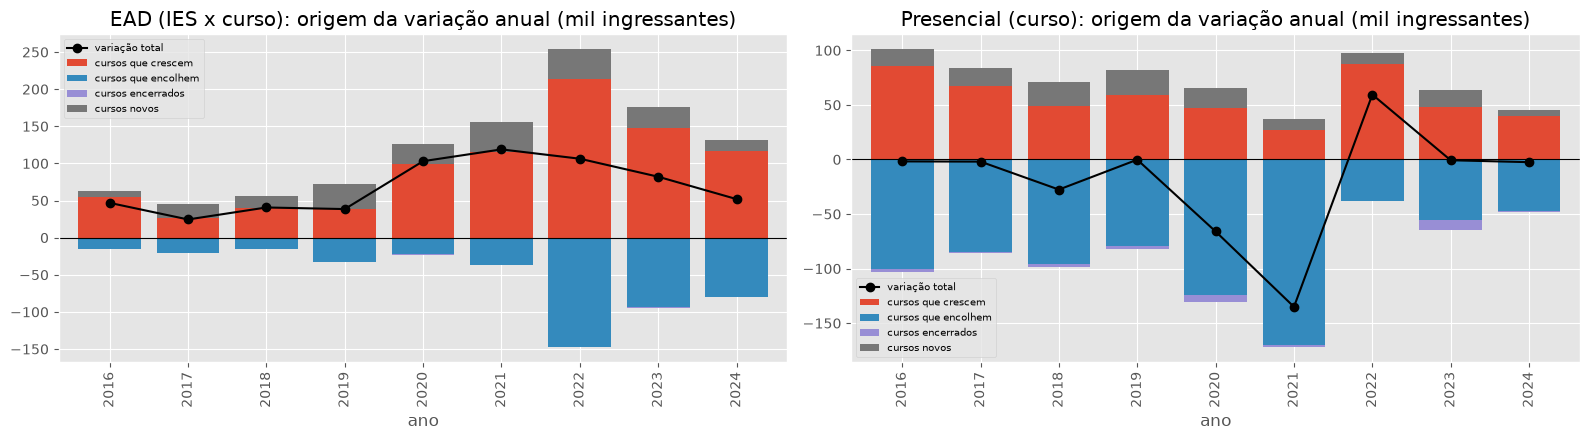


EAD (IES x curso) – efeitos em número de ingressantes


,cursos que crescem,cursos que encolhem,cursos encerrados,cursos novos,variação total
ano,,,,,
2016,54676,-15139,-522,7849,46864
2017,26233,-20825,0,19116,24524
2018,40231,-15370,-2,15808,40667
2019,38317,-33250,-134,33588,38521
2020,99865,-21629,-1444,26232,103024
2021,115315,-37318,-59,40961,118899
2022,213824,-147394,-76,39985,106339
2023,147059,-93803,-375,29202,82083
2024,116634,-79496,-125,14934,51947


Parcela do ganho bruto (crescem + novos) vinda de cursos novos, média 2016–2024: 24.5%

Presencial (curso) – efeitos em número de ingressantes


,cursos que crescem,cursos que encolhem,cursos encerrados,cursos novos,variação total
ano,,,,,
2016,85792,-100387,-2400,15232,-1763
2017,67696,-84350,-1066,15761,-1959
2018,48838,-95386,-2956,21924,-27580
2019,59204,-79329,-2803,22752,-176
2020,47604,-123849,-7188,17454,-65979
2021,26744,-169621,-2370,10206,-135041
2022,87318,-37767,-548,10455,59458
2023,48263,-55788,-8501,15309,-717
2024,40230,-47076,-906,5285,-2467


Parcela do ganho bruto (crescem + novos) vinda de cursos novos, média 2016–2024: 21.5%


In [12]:
def decompor_crescimento(base, keys):
    """Divide a variação anual do total de ingressantes em quatro efeitos (soma exata da variação)."""
    total = base.groupby("ANO")["ING_NOVA"].sum()
    pn = painel_ead(base, keys)
    linhas = []
    for T, g in pn.groupby("T"):
        existentes = g[g["FECHOU"] == 0]
        delta = existentes["y_next"] - existentes["y0"]
        linhas.append({"ano": T + 1,
                       "cursos que crescem": delta[delta > 0].sum(),
                       "cursos que encolhem": delta[delta < 0].sum(),
                       "cursos encerrados": -g.loc[g["FECHOU"] == 1, "y0"].sum(),
                       "cursos novos": total.loc[T + 1] - existentes["y_next"].sum()})
    t = pd.DataFrame(linhas).set_index("ano")
    t["variação total"] = t.sum(axis=1)
    assert (t["variação total"] == total.diff().loc[t.index]).all()   # verificação: os efeitos somam a variação
    return t


decomp = {"EAD (IES x curso)": decompor_crescimento(ead, ["CO_IES", "CO_CURSO"]),
          "Presencial (curso)": decompor_crescimento(pres_base, ["CO_IES", "CO_CURSO", "CO_MUNICIPIO"])}
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for a, (nome, t) in zip(ax, decomp.items()):
    (t.drop(columns="variação total") / 1e3).plot.bar(stacked=True, ax=a, width=.8)
    a.plot(range(len(t)), t["variação total"] / 1e3, "k-o", label="variação total")
    a.axhline(0, c="k", lw=.8)
    a.set_title(f"{nome}: origem da variação anual (mil ingressantes)"); a.set_xlabel("ano"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
for nome, t in decomp.items():
    print(f"\n{nome} – efeitos em número de ingressantes")
    display(t.round(0).astype(int))
    pos = t[["cursos que crescem", "cursos novos"]]
    print("Parcela do ganho bruto (crescem + novos) vinda de cursos novos, média 2016–2024:",
          f"{(pos['cursos novos'] / pos.sum(axis=1)).mean() * 100:.1f}%")

**3.3 Onde o modelo erra: porte, área e encerramento.** Aplica-se o modelo proporcional (`y(t+1) = b · y(t)`, treinado até 2022) ao ano de teste e o erro é detalhado por:

- **porte do curso** (ingressantes em *t*): mostra se o erro está nos cursos grandes ou nos pequenos;
- **continuidade:** compara cursos que continuam com os que são encerrados;
- **área de formação (CINE):** mostra áreas com viés sistemático.

Para cada grupo são apresentados: a parcela dos ingressantes reais, a **parcela do erro total**, o WAPE e o viés (positivo = o modelo superestima). Quando a parcela do erro é muito maior que a parcela dos ingressantes, o grupo é a principal fonte de erro.

In [13]:
def diagnostico_erro(pn, nome):
    """Erro do modelo proporcional no ano-alvo 2024 (treino até 2022), por porte, continuidade e área."""
    tr, te = pn[pn["T"] <= 2022], pn[pn["T"] == 2023].copy()
    m = LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"])
    te["pred"] = np.clip(m.predict(te[["y0"]]), 0, None)
    te["erro"] = te["pred"] - te["y_nextB"]
    te["erro_abs"] = te["erro"].abs()
    te["porte"] = pd.cut(te["y0"], [-1, 0, 10, 50, 200, np.inf], labels=["0", "1–10", "11–50", "51–200", "> 200"])
    te["continuidade"] = np.where(te["FECHOU"] == 1, "encerrado em 2024", "continua em 2024")

    def resumo(g):
        real = g["y_nextB"].sum()
        return pd.Series({"cursos": len(g),
                          "% dos ingressantes": real / te["y_nextB"].sum() * 100,
                          "% do erro total": g["erro_abs"].sum() / te["erro_abs"].sum() * 100,
                          "WAPE": g["erro_abs"].sum() / real if real > 0 else np.nan,       # sem alunos reais, o WAPE não se aplica
                          "viés %": g["erro"].sum() / real * 100 if real > 0 else np.nan})
    print(f"===== {nome}: WAPE total {te['erro_abs'].sum() / te['y_nextB'].sum():.3f} =====")
    for col in ["porte", "continuidade"]:
        display(te.groupby(col, observed=True).apply(resumo).round(2))
    if "AREA" in te:
        a = te.groupby("AREA").apply(resumo)
        display(a[a["cursos"] >= 20].sort_values("% do erro total", ascending=False).round(2).head(8))


diagnostico_erro(p_curso, "EAD – IES x curso")
diagnostico_erro(p_pres_curso, "Presencial – por curso")

===== EAD – IES x curso: WAPE total 0.274 =====


,cursos,% dos ingressantes,% do erro total,WAPE,viés %
porte,,,,,
0,820.0,0.27,0.97,1.00,-100.00
1–10,1452.0,1.64,5.09,0.85,-51.69
11–50,1406.0,6.21,12.45,0.55,-21.16
51–200,1204.0,18.00,25.71,0.39,-5.04
> 200,695.0,73.89,55.78,0.21,-7.01


,cursos,% dos ingressantes,% do erro total,WAPE,viés %
continuidade,,,,,
continua em 2024,5278.0,100.0,99.94,0.27,-8.53
encerrado em 2024,299.0,0.0,0.06,NaN,NaN


,cursos,% dos ingressantes,% do erro total,WAPE,viés %
AREA,,,,,
"Negócios, administração e direito",1929.0,36.86,32.53,0.24,-9.21
Saúde e bem-estar,476.0,14.81,18.62,0.35,-13.16
Educação,1031.0,18.59,17.76,0.26,-6.64
Computação e Tecnologias da Informação e Comunicação (TIC),688.0,12.32,10.78,0.24,-6.09
"Engenharia, produção e construção",492.0,5.47,6.34,0.32,-8.44
Serviços,333.0,4.55,5.60,0.34,-4.91
Artes e humanidades,300.0,3.23,3.87,0.33,-6.74
"Ciências sociais, comunicação e informação",204.0,2.04,2.19,0.29,0.48


===== Presencial – por curso: WAPE total 0.289 =====


,cursos,% dos ingressantes,% do erro total,WAPE,viés %
porte,,,,,
0,1270.0,1.11,3.85,1.00,-100.00
1–10,1139.0,2.27,7.19,0.92,-28.86
11–50,2337.0,20.68,29.68,0.41,-9.87
51–200,1751.0,50.91,44.82,0.25,-8.69
> 200,242.0,25.03,14.45,0.17,-8.44


,cursos,% dos ingressantes,% do erro total,WAPE,viés %
continuidade,,,,,
continua em 2024,6200.0,100.0,99.11,0.29,-10.6
encerrado em 2024,539.0,0.0,0.89,NaN,NaN


,cursos,% dos ingressantes,% do erro total,WAPE,viés %
AREA,,,,,
"Negócios, administração e direito",1849.0,28.28,27.36,0.28,-11.17
Saúde e bem-estar,1255.0,25.56,23.48,0.27,-11.27
"Ciências sociais, comunicação e informação",452.0,12.59,11.66,0.27,-15.62
Computação e Tecnologias da Informação e Comunicação (TIC),560.0,11.73,10.91,0.27,-10.57
"Engenharia, produção e construção",1117.0,7.51,10.55,0.41,1.84
Educação,661.0,4.06,5.16,0.37,-8.32
Artes e humanidades,377.0,3.08,3.62,0.34,0.58
"Agricultura, silvicultura, pesca e veterinária",152.0,3.81,2.68,0.20,-8.48


**3.4 Por que os modelos em escala logarítmica pioraram.** O modelo em log (com a correção de Duan) otimiza o erro *relativo* e trata um curso de 5 alunos e um de 500 como igualmente importantes. Ao reconverter a previsão para número de alunos, pequenos desvios nos cursos grandes são multiplicados. A comparação a seguir usa as mesmas variáveis (`y0` e `y1`) em três modelos e mostra o **viés por porte**: valores positivos indicam superestimação.

In [14]:
def vies_por_porte(pn, nome):
    tr, te = pn[pn["T"] <= 2022], pn[pn["T"] == 2023].copy()
    F2 = ["y0", "y1"]
    nivel = LinearRegression().fit(tr[F2], tr["y_nextB"]).predict(te[F2])
    ml = LinearRegression().fit(np.log1p(tr[F2]), np.log1p(tr["y_nextB"]))
    duan = np.exp(np.log1p(tr["y_nextB"]) - ml.predict(np.log1p(tr[F2]))).mean()
    logp = np.exp(ml.predict(np.log1p(te[F2]))) * duan - 1
    prop = LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"]).predict(te[["y0"]])
    te["porte"] = pd.cut(te["y0"], [-1, 0, 10, 50, 200, np.inf], labels=["0", "1–10", "11–50", "51–200", "> 200"])
    saida = {}
    for rotulo, pred in [("OLS nível", nivel), ("OLS log1p", logp), ("Proporcional", prop)]:
        pred = np.clip(pred, 0, None)
        e = (pred - te["y_nextB"]).groupby(te["porte"], observed=True).sum() / te["y_nextB"].groupby(te["porte"], observed=True).sum().clip(lower=1) * 100
        e["TOTAL"] = (pred - te["y_nextB"]).sum() / te["y_nextB"].sum() * 100
        saida[rotulo] = e
    print(f"===== {nome}: viés % por porte do curso (ano-alvo 2024) =====")
    display(pd.DataFrame(saida).round(1))


vies_por_porte(p_curso, "EAD – IES x curso")
vies_por_porte(p_pres_curso, "Presencial – por curso")

===== EAD – IES x curso: viés % por porte do curso (ano-alvo 2024) =====


,OLS nível,OLS log1p,Proporcional
porte,,,
0,1040.3,-27.8,-100.0
1–10,280.5,35.0,-51.7
11–50,62.3,73.5,-21.2
51–200,17.5,84.6,-5.0
> 200,-7.4,49.3,-7.0
TOTAL,8.9,56.7,-8.5


===== Presencial – por curso: viés % por porte do curso (ano-alvo 2024) =====


,OLS nível,OLS log1p,Proporcional
porte,,,
0,4.1,-55.9,-100.0
1–10,15.7,48.1,-28.9
11–50,-0.9,43.1,-9.9
51–200,-6.4,25.8,-8.7
> 200,-8.2,9.0,-8.4
TOTAL,-5.1,24.8,-10.3


**3.5 Conclusões da análise diagnóstica.**

- **Origem da variação.** No EAD, o crescimento vem quase todo de cursos que já existiam: os cursos novos respondem por cerca de 25% do ganho bruto e o encerramento de cursos é desprezível (no máximo cerca de 1,4 mil alunos por ano, em 2020). No presencial, os cursos novos respondem por cerca de 22% do ganho bruto, mas o resultado líquido é determinado por movimentos grandes e opostos: em 2021, por exemplo, os cursos que encolheram perderam cerca de 170 mil ingressantes e os que cresceram ganharam cerca de 27 mil (variação total de −135 mil). Isso explica por que a previsão do total é mais fácil do que a previsão de cada curso: os erros individuais se compensam parcialmente.
- **Onde o modelo erra.** O erro em número de alunos se concentra nos cursos grandes (no EAD, os cursos com mais de 200 ingressantes são 74% do volume e 56% do erro), mas o erro *relativo* é menor neles (WAPE de 0,21 no EAD e 0,17 no presencial). Os cursos pequenos (até 10 ingressantes) têm erro relativo de 85% a 100%, porém pesam menos de 4% do volume. Os cursos que são encerrados contribuem com menos de 1% do erro (0,06% no EAD e 0,89% no presencial), portanto **o encerramento de cursos não é a principal fonte de erro**. Por área de formação, o EAD tem erro relativamente homogêneo (WAPE de 0,24 a 0,35); no presencial, Engenharia (0,41) e Educação (0,37) são as áreas mais difíceis. Em quase todos os recortes o viés é negativo (o modelo tende a subestimar entre 5% e 16%), consistente com mercados que cresceram além da inércia do ano anterior.
- **Por que o log piorou.** O modelo em escala logarítmica superestima em quase todos os portes: no total, +57% no EAD e +25% no presencial (nos cursos de 11 a 200 ingressantes, a superestimação passa de 70% no EAD). O modelo linear em nível tem bom comportamento nos cursos grandes (viés de −7% no EAD), mas superestima fortemente os cursos pequenos por causa do intercepto. O modelo proporcional, sem intercepto, tem viés estável e moderado (entre −5% e −9% nos cursos grandes).

**Implicações para a modelagem e para a decisão.** (i) Manter o modelo proporcional sem intercepto como modelo principal. (ii) Concentrar o acompanhamento nos cursos grandes, que determinam a maior parte do resultado. (iii) Não interpretar previsões individuais de cursos muito pequenos ou sem ingressantes no ano anterior, pois o erro relativo é alto. (iv) Para decisões de capacidade, preferir o nível da instituição, em que os erros individuais se compensam.

## 4. Análise preditiva – ensino presencial: o que deve acontecer?

**Delineamento.** Para cada curso e ano *t*, o modelo recebe as informações disponíveis até *t* (ingressantes, vagas, inscrições etc.) e prevê o número de ingressantes em vagas novas em *t+1*. Todas as abordagens comparadas a seguir usam exatamente as mesmas informações e a mesma forma de avaliação, de modo que a diferença de desempenho se deva somente ao método.

**Cuidado central: vazamento de informação.** Nenhuma variável pode conter dado de *t+1* ou posterior, pois isso tornaria a previsão artificialmente boa e inútil na prática.

**4.1 Construção do painel de modelagem.** Nesta etapa:

- filtra-se a modalidade **Presencial** (a única com vagas e inscrições registradas);
- cria-se um identificador de curso (instituição + curso + município) para acompanhá-lo ao longo dos anos;
- para cada curso e ano, buscam-se os valores dos anos anteriores (*lags*) e o valor do ano seguinte (o alvo);
- calculam-se indicadores como taxa de ocupação (ingressantes ÷ vagas), relação inscrições/vagas e variação anual;
- cursos que não aparecem em *t+1* recebem alvo igual a zero (cenário **B**, interpretado como encerramento) ou são desconsiderados (cenário **A**), e os dois cenários são reportados.

O ano de 2024 não entra no painel como ponto de partida, pois é reservado como teste final (*holdout*).

In [15]:
from sklearn.linear_model import LinearRegression, Ridge, ElasticNetCV, LassoCV, RidgeCV, PoissonRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

Y = "QTD_INGRESSANTES_VAGAS_NOVAS"
pres = df[df["MODALIDADE_ENSINO"] == "Presencial"].copy()
pres["CURSO_ID"] = (pres["COD_IES"].astype(str) + "_" + pres["COD_CURSO"].astype(str)
                    + "_" + pres["COD_MUNICIPIO"].astype(str))
assert not pres.duplicated(["CURSO_ID", "ANO_CENSO"]).any()
print(f"Presencial: {len(pres):,} linhas, {pres['CURSO_ID'].nunique():,} cursos (IES x curso x municipio)")

num = [Y, "QTD_VAGAS_NOVAS", "QTD_INSCRICOES_VAGAS_NOVAS", "QTD_INGRESSANTES_TOTAL",
       "QTD_CONCLUINTES", "QTD_FINANCIAMENTO", "QTD_PROUNI"]
base = pres[["CURSO_ID", "ANO_CENSO", "COD_IES", "COD_MUNICIPIO", "NOME_AREA_GERAL_CINE",
             "ORGANIZACAO_ACADEMICA"] + num].rename(columns={"ANO_CENSO": "T"})
lk = base.set_index(["CURSO_ID", "T"])


def lookup(col, lag):
    """Valor de `col` em t-lag (lag>0) ou t+|lag| (lag<0) por curso; NaN se o curso nao existe nesse ano."""
    idx = pd.MultiIndex.from_arrays([base["CURSO_ID"], base["T"] - lag])
    return lk[col].reindex(idx).to_numpy()


p = base.copy()
p["y0"] = p[Y]
p["y1"] = lookup(Y, 1)
p["y2"] = lookup(Y, 2)
p["TEM_LAG1"] = p["y1"].notna().astype(int)
p["TEM_LAG2"] = p["y2"].notna().astype(int)
p["IDADE"] = p.groupby("CURSO_ID")["T"].transform(lambda s: s - s.min())  # anos desde a 1a aparicao (<=2015 censurado)
p["y_next"] = lookup(Y, -1)            # NaN = curso sem linha em t+1 (fechou / saiu da base)
p["FECHOU"] = p["y_next"].isna().astype(int)
for c_ in ["y1", "y2"]:
    p[c_] = p[c_].fillna(0)
p["vagas1"] = pd.Series(lookup("QTD_VAGAS_NOVAS", 1), index=p.index).fillna(0)
p["insc1"] = pd.Series(lookup("QTD_INSCRICOES_VAGAS_NOVAS", 1), index=p.index).fillna(0)
p["vagas0"] = p["QTD_VAGAS_NOVAS"]
p["insc0"] = p["QTD_INSCRICOES_VAGAS_NOVAS"]
p["ingtot0"] = p["QTD_INGRESSANTES_TOTAL"]
p["concl0"] = p["QTD_CONCLUINTES"]
p["fin0"] = p["QTD_FINANCIAMENTO"]
p["prouni0"] = p["QTD_PROUNI"]
p["ma3"] = (p["y0"] + p["y1"] + p["y2"]) / (1 + p["TEM_LAG1"] + p["TEM_LAG2"])
p["SEM_OFERTA"] = (p["vagas0"] == 0).astype(int)
p["OCUP0"] = np.where(p["vagas0"] > 0, p["y0"] / p["vagas0"].replace(0, np.nan), 0.0)
p["OCUP0"] = p["OCUP0"].clip(0, 5)
p["DEMANDA0"] = np.where(p["vagas0"] > 0, p["insc0"] / p["vagas0"].replace(0, np.nan), 0.0)
p["DEMANDA0"] = pd.Series(p["DEMANDA0"]).clip(0, 50).to_numpy()
p["YOY"] = np.where(p["y1"] > 0, (p["y0"] - p["y1"]) / p["y1"].replace(0, np.nan), 0.0)
p["YOY"] = pd.Series(p["YOY"]).clip(-1, 5).fillna(0).to_numpy()

# alvo cenario B: curso que fechou = 0 ingressantes; cenario A: so cursos que continuam
p["y_next_B"] = p["y_next"].fillna(0)
p = p[p["T"] <= 2023].copy()           # t=2023 -> alvo 2024 (holdout)
print("Linhas do painel (t=2015..2023):", len(p))
print("Cursos que nao aparecem em t+1:", f"{p['FECHOU'].mean():.1%}")
print(p.groupby("T")["FECHOU"].mean().round(3).to_string())

NUM_FEATS = ["y0", "y1", "y2", "ma3", "vagas0", "vagas1", "insc0", "insc1", "ingtot0", "concl0", "fin0", "prouni0"]
FLAG_FEATS = ["TEM_LAG1", "TEM_LAG2", "SEM_OFERTA"]
RATIO_FEATS = ["OCUP0", "DEMANDA0", "YOY"]
FEATS = NUM_FEATS + FLAG_FEATS + RATIO_FEATS
CAT = ["NOME_AREA_GERAL_CINE", "ORGANIZACAO_ACADEMICA"]

Presencial: 68,957 linhas, 10,174 cursos (IES x curso x municipio)


Linhas do painel (t=2015..2023): 62523
Cursos que nao aparecem em t+1: 6.6%
T
2015    0.039
2016    0.073
2017    0.052
2018    0.061
2019    0.064
2020    0.081
2021    0.061
2022    0.078
2023    0.080


**4.2 Exploração no recorte de modelagem.** Os gráficos e tabelas desta etapa mostram a distribuição do número de ingressantes (muito assimétrica: muitos cursos pequenos e poucos muito grandes), a correlação entre o ano atual e o seguinte, a razão entre o total de ingressantes em *t+1* e em *t* (que revela os choques de mercado, como 2020–2021) e a ocupação média por área de formação.

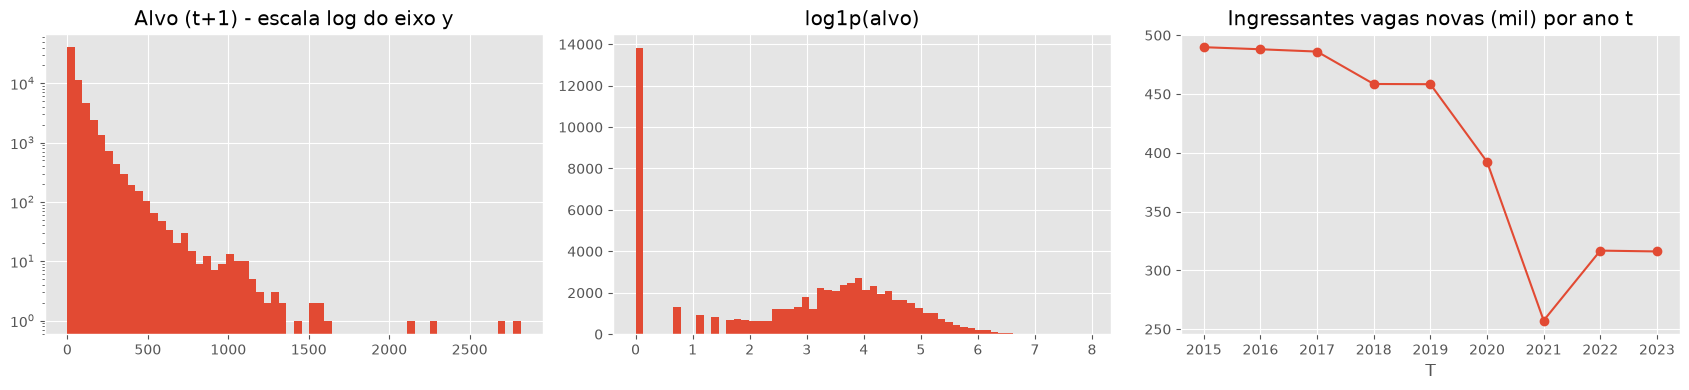

Alvo (t+1, cenario B): zeros = 22.1% | corr(y0, y_next) = 0.891 | corr(log) = 0.815
Razao media y_next/y0 por ano (soma/soma):
T
2015    0.965
2016    0.964
2017    0.898
2018    0.950
2019    0.818
2020    0.630
2021    1.190
2022    0.949
2023    0.975
                                                        n      ing    vagas  \
NOME_AREA_GERAL_CINE                                                          
Negócios, administração e direito                   18373  1213493  3419824   
Engenharia, produção e construção                   10556   462367  1701094   
Saúde e bem-estar                                    9864   800131  1733930   
Educação                                             7824   288048  1058473   
Computação e Tecnologias da Informação e Comuni...   5051   249403   789188   
Ciências sociais, comunicação e informação           3421   306781   629495   
Artes e humanidades                                  3253   126941   389513   
Serviços                          

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(p["y_next_B"], bins=60, log=True); ax[0].set_title("Alvo (t+1) - escala log do eixo y")
ax[1].hist(np.log1p(p["y_next_B"]), bins=60); ax[1].set_title("log1p(alvo)")
(p.groupby("T")[["y0"]].sum() / 1e3).plot(ax=ax[2], legend=False, marker="o")
ax[2].set_title("Ingressantes vagas novas (mil) por ano t")
plt.tight_layout(); plt.show()

print("Alvo (t+1, cenario B): zeros =", f"{(p['y_next_B'] == 0).mean():.1%}",
      "| corr(y0, y_next) =", round(p[["y0", "y_next_B"]].corr().iloc[0, 1], 3),
      "| corr(log) =", round(np.log1p(p[["y0", "y_next_B"]]).corr().iloc[0, 1], 3))
print("Razao media y_next/y0 por ano (soma/soma):")
print((p.groupby("T")["y_next_B"].sum() / p.groupby("T")["y0"].sum()).round(3).to_string())
occ = p.groupby("NOME_AREA_GERAL_CINE").agg(n=("y0", "size"), ing=("y0", "sum"), vagas=("vagas0", "sum"))
occ["ocupacao"] = (occ["ing"] / occ["vagas"]).round(2)
print(occ.sort_values("n", ascending=False).head(8))

**4.3 Esquema de avaliação.** O desempenho é medido por **validação temporal expansiva**: o modelo é treinado com os anos até *T−1* e testado em *T* (alvo *T+1*), repetindo-se o processo para *T* = 2018 a 2022, o que produz testes sobre os anos de 2019 a 2023. Em seguida, o ano de 2024 é usado uma única vez como teste final.

As funções abaixo (i) calculam as métricas MAE, RMSE, WAPE, viés e R², (ii) executam a validação para qualquer modelo e (iii) acumulam os resultados em uma tabela comum, permitindo a comparação direta entre abordagens.

In [17]:
ORIGENS = [2018, 2019, 2020, 2021, 2022]   # treina com t<=T-1 (alvo<=T), testa t=T (alvo T+1 = 2019..2023)
HOLDOUT = 2023                              # alvo 2024: so no fim


def metricas(y, yhat):
    e = yhat - y
    return dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()),
                WAPE=np.abs(e).sum() / y.sum(), VIES_pct=e.sum() / y.sum() * 100,
                R2=1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum())


def target_col(cenario):
    return "y_next_B" if cenario == "B" else "y_next"


def avaliar(fit_predict, nome, cenario="B", origens=ORIGENS, extra=None):
    """fit_predict(train, test, ycol) -> pred (escala original, >=0). Retorna (resumo, previsoes)."""
    ycol = target_col(cenario)
    linhas, preds = [], []
    for T in origens:
        tr = p[(p["T"] <= T - 1)]
        te = p[(p["T"] == T)]
        if cenario == "A":
            tr, te = tr[tr[ycol].notna()], te[te[ycol].notna()]
        pred = np.clip(fit_predict(tr, te, ycol), 0, None)
        m = metricas(te[ycol].to_numpy(), pred)
        m.update(origem=T, alvo=T + 1, n=len(te))
        linhas.append(m)
        o = te[["CURSO_ID", "COD_IES", "NOME_AREA_GERAL_CINE", "T", "y0"]].copy()
        o["real"], o["pred"] = te[ycol].to_numpy(), pred
        preds.append(o)
    res = pd.DataFrame(linhas)
    resumo = res[["MAE", "RMSE", "WAPE", "VIES_pct", "R2"]].mean().to_dict()
    resumo.update(modelo=nome, cenario=cenario, WAPE_2020=res.loc[res.alvo == 2020, "WAPE"].iloc[0],
                  WAPE_2023=res.loc[res.alvo == 2023, "WAPE"].iloc[0])
    return resumo, pd.concat(preds), res


RESULTADOS, PREDS = [], {}


def rodar(nome, fn, cenarios=("B", "A")):
    for c_ in cenarios:
        r, pr, _ = avaliar(fn, nome, c_)
        RESULTADOS.append(r)
        PREDS[(nome, c_)] = pr
    return pd.DataFrame(RESULTADOS).query("modelo == @nome")[["modelo", "cenario", "MAE", "WAPE", "RMSE", "VIES_pct", "R2"]]


def L(df_, cols):
    return np.log1p(df_[cols].clip(lower=0))

**4.4 Abordagem 0 – Linhas de base.** São duas regras sem estatística: (a) "o ano seguinte repete o ano atual" e (b) "o ano seguinte é a média dos três últimos anos". Servem de régua mínima: um modelo só se justifica se superar essas regras de forma consistente.

In [18]:
rodar("0a Baseline y(t)", lambda tr, te, y: te["y0"].to_numpy())
rodar("0b Baseline media 3a", lambda tr, te, y: te["ma3"].to_numpy())

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
2,0b Baseline media 3a,B,25.799020,0.575215,45.854651,31.492821,0.634416
3,0b Baseline media 3a,A,26.638122,0.552428,46.520205,29.214182,0.639850


**4.5 Abordagem 1 – Regressão linear (OLS) na escala original.** Ajusta-se uma única equação linear que combina todas as variáveis (ingressantes passados, vagas, inscrições, ocupação etc.) para estimar o alvo. É a forma mais direta e interpretável de regressão linear; sua limitação é tratar igualmente cursos pequenos e muito grandes e poder produzir valores negativos (que são truncados em zero).

In [19]:
def ols_raw(tr, te, y):
    m = LinearRegression().fit(tr[FEATS], tr[y])
    return m.predict(te[FEATS])


rodar("1 OLS nivel", ols_raw)

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
4,1 OLS nivel,B,21.281148,0.471417,40.616735,5.772319,0.723100
5,1 OLS nivel,A,22.227298,0.458749,41.277857,5.313515,0.725625


**4.6 Abordagem 2 – Regressão linear em escala logarítmica.** Aplica-se `log(1 + x)` ao alvo e às variáveis, o que reduz a assimetria e faz os coeficientes representarem variações percentuais. Como o modelo é ajustado no log, a previsão precisa ser reconvertida à escala de alunos; para isso se usa o fator de correção de Duan (*smearing*), que evita subestimar a média.

In [20]:
LOGF = NUM_FEATS
def _X_log(d):
    return np.hstack([L(d, LOGF).to_numpy(), d[FLAG_FEATS + RATIO_FEATS].to_numpy()])


def ols_log(tr, te, y):
    m = LinearRegression().fit(_X_log(tr), np.log1p(tr[y]))
    smear = np.exp(np.log1p(tr[y]) - m.predict(_X_log(tr))).mean()
    return np.exp(m.predict(_X_log(te))) * smear - 1


rodar("2 OLS log1p", ols_log)

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
6,2 OLS log1p,B,28.905001,0.633294,65.771036,37.672160,0.261653
7,2 OLS log1p,A,30.662710,0.625636,67.175799,38.453426,0.260175


**4.7 Abordagem 3 – Modelar a variação.** Em vez de prever o número de alunos, prevê-se a **variação** entre *t* e *t+1* (em log) e soma-se ao valor de *t*. Assim, o porte do curso deixa de ser parte do problema e o modelo concentra-se no que muda de um ano para o outro.

In [21]:
def ols_delta(tr, te, y):
    d = np.log1p(tr[y]) - np.log1p(tr["y0"])
    m = LinearRegression().fit(_X_log(tr), d)
    return np.expm1(np.log1p(te["y0"]) + m.predict(_X_log(te)))


rodar("3 OLS delta-log", ols_delta)

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
8,3 OLS delta-log,B,21.931834,0.479630,43.367214,-15.707409,0.694039
9,3 OLS delta-log,A,22.794582,0.465456,44.032208,-13.769449,0.697331


**4.8 Abordagem 4 – Regressão regularizada (Ridge, Lasso e ElasticNet).** Variáveis como ingressantes de *t* e de *t−1*, ou vagas e inscrições, são fortemente correlacionadas entre si. Os métodos regularizados penalizam coeficientes grandes e, no caso do Lasso, eliminam variáveis pouco úteis, tornando o modelo mais estável. A intensidade da penalização é escolhida por validação cruzada que respeita a ordem do tempo.

In [22]:
def _reg(model_cls, delta):
    def f(tr, te, y):
        tr = tr.sort_values("T")
        tgt = (np.log1p(tr[y]) - np.log1p(tr["y0"])) if delta else np.log1p(tr[y])
        sc = StandardScaler().fit(_X_log(tr))
        cv = TimeSeriesSplit(n_splits=4)
        m = model_cls(cv=cv).fit(sc.transform(_X_log(tr)), tgt)
        out = m.predict(sc.transform(_X_log(te)))
        if delta:
            return np.expm1(np.log1p(te["y0"]) + out)
        smear = np.exp(tgt - m.predict(sc.transform(_X_log(tr)))).mean()
        return np.exp(out) * smear - 1
    return f


rodar("4a Ridge log1p", _reg(lambda cv: RidgeCV(alphas=np.logspace(-3, 3, 13), cv=cv), False))
rodar("4b Lasso delta-log", _reg(lambda cv: LassoCV(cv=cv, max_iter=5000), True))
rodar("4c ElasticNet log1p", _reg(lambda cv: ElasticNetCV(l1_ratio=[.2, .5, .8], cv=cv, max_iter=5000), False))

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
14,4c ElasticNet log1p,B,27.872819,0.612399,60.949907,34.885628,0.356598
15,4c ElasticNet log1p,A,29.511974,0.604088,61.936281,35.679247,0.359645


**4.9 Abordagem 5 – Modelo de Poisson (GLM com ligação log).** Trata o alvo como uma **contagem** (número inteiro, não negativo), o que é mais adequado a "quantidade de alunos". Embora seja linear no preditor, garante previsões não negativas sem necessidade de truncamento.

In [23]:
def poisson(tr, te, y):
    sc = StandardScaler().fit(_X_log(tr))
    m = PoissonRegressor(alpha=1e-3, max_iter=1000).fit(sc.transform(_X_log(tr)), tr[y])
    return m.predict(sc.transform(_X_log(te)))


rodar("5 Poisson GLM", poisson)

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
16,5 Poisson GLM,B,21.356019,0.473001,40.469713,7.202407,0.723309
17,5 Poisson GLM,A,22.363341,0.461424,41.108746,6.780494,0.726479


**4.10 Abordagem 6 – Efeitos fixos.** Acrescentam-se ao modelo logarítmico variáveis categóricas (área CINE, organização acadêmica, município e instituição) para verificar se identificar *onde* e *qual* é o curso melhora a previsão além do próprio histórico dele.

In [24]:
def _fe(cols, cat_top=None):
    def f(tr, te, y):
        trc, tec = tr.copy(), te.copy()
        if "COD_MUNICIPIO" in cols:
            top = trc["COD_MUNICIPIO"].value_counts().head(40).index
            for d_ in (trc, tec):
                d_["COD_MUNICIPIO"] = d_["COD_MUNICIPIO"].where(d_["COD_MUNICIPIO"].isin(top), -1)
        ct = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cols)], remainder="drop")
        Xc = ct.fit_transform(trc)
        Xn = StandardScaler().fit(_X_log(trc))
        from scipy.sparse import hstack, csr_matrix
        Xtr = hstack([csr_matrix(Xn.transform(_X_log(trc))), Xc]).tocsr()
        Xte = hstack([csr_matrix(Xn.transform(_X_log(tec))), ct.transform(tec)]).tocsr()
        tgt = np.log1p(trc[y])
        m = Ridge(alpha=10.0).fit(Xtr, tgt)
        smear = np.exp(tgt - m.predict(Xtr)).mean()
        return np.exp(m.predict(Xte)) * smear - 1
    return f


rodar("6a Ridge + CINE+ORG", _fe(["NOME_AREA_GERAL_CINE", "ORGANIZACAO_ACADEMICA"]))
rodar("6b Ridge + CINE+ORG+MUN", _fe(["NOME_AREA_GERAL_CINE", "ORGANIZACAO_ACADEMICA", "COD_MUNICIPIO"]))
rodar("6c Ridge + CINE+ORG+IES", _fe(["NOME_AREA_GERAL_CINE", "ORGANIZACAO_ACADEMICA", "COD_IES"]))

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
22,6c Ridge + CINE+ORG+IES,B,31.189628,0.682776,72.126603,43.511295,0.127132
23,6c Ridge + CINE+ORG+IES,A,33.504522,0.682016,75.397521,44.578529,0.087083


**4.11 Abordagem 7 – Regressão ponderada (WLS).** Cursos grandes pesam mais no planejamento de recursos. A ponderação atribui maior peso a esses cursos durante o ajuste, aproximando o critério de otimização do critério de negócio.

In [25]:
def wls_log(tr, te, y):
    w = 1 + tr["y0"].to_numpy()
    m = LinearRegression().fit(_X_log(tr), np.log1p(tr[y]), sample_weight=w)
    r = np.log1p(tr[y]) - m.predict(_X_log(tr))
    smear = np.average(np.exp(r), weights=w)
    return np.exp(m.predict(_X_log(te))) * smear - 1


rodar("7 WLS log1p (peso 1+y0)", wls_log)

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
24,7 WLS log1p (peso 1+y0),B,21.410091,0.472904,44.317662,3.399834,0.666351
25,7 WLS log1p (peso 1+y0),A,22.239466,0.457673,44.057418,2.616147,0.684161


**4.12 Comparativo parcial.** A tabela reúne, para cada abordagem, as métricas médias da validação temporal nos dois cenários (B: cursos encerrados contam como zero; A: apenas cursos que continuam), ordenadas pelo WAPE. Menores valores de WAPE e viés próximo de zero indicam melhor desempenho.

In [26]:
res = pd.DataFrame(RESULTADOS)
cols = ["modelo", "cenario", "MAE", "WAPE", "RMSE", "VIES_pct", "R2", "WAPE_2020", "WAPE_2023"]
tabB = res[res.cenario == "B"][cols].sort_values("WAPE")
display(tabB.round(3).reset_index(drop=True))
display(res[res.cenario == "A"][cols].sort_values("WAPE").round(3).reset_index(drop=True))

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2,WAPE_2020,WAPE_2023
0,1 OLS nivel,B,21.281,0.471,40.617,5.772,0.723,0.441,0.396
1,7 WLS log1p (peso 1+y0),B,21.410,0.473,44.318,3.400,0.666,0.459,0.406
2,5 Poisson GLM,B,21.356,0.473,40.470,7.202,0.723,0.436,0.408
3,0a Baseline y(t),B,21.516,0.478,42.337,15.125,0.690,0.476,0.374
4,3 OLS delta-log,B,21.932,0.480,43.367,-15.707,0.694,0.417,0.479
5,4b Lasso delta-log,B,21.927,0.480,42.798,-17.338,0.701,0.413,0.481
6,0b Baseline media 3a,B,25.799,0.575,45.855,31.493,0.634,0.512,0.459
7,4c ElasticNet log1p,B,27.873,0.612,60.950,34.886,0.357,0.676,0.443
8,4a Ridge log1p,B,28.403,0.623,63.694,36.326,0.305,0.687,0.450
9,2 OLS log1p,B,28.905,0.633,65.771,37.672,0.262,0.703,0.452


,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2,WAPE_2020,WAPE_2023
0,7 WLS log1p (peso 1+y0),A,22.239,0.458,44.057,2.616,0.684,0.440,0.375
1,1 OLS nivel,A,22.227,0.459,41.278,5.314,0.726,0.425,0.370
2,4b Lasso delta-log,A,22.608,0.461,42.701,-16.574,0.717,0.398,0.451
3,5 Poisson GLM,A,22.363,0.461,41.109,6.780,0.726,0.422,0.383
4,0a Baseline y(t),A,22.466,0.465,42.705,13.820,0.697,0.457,0.346
5,3 OLS delta-log,A,22.795,0.465,44.032,-13.769,0.697,0.402,0.448
6,0b Baseline media 3a,A,26.638,0.552,46.520,29.214,0.640,0.490,0.427
7,4c ElasticNet log1p,A,29.512,0.604,61.936,35.679,0.360,0.661,0.403
8,4a Ridge log1p,A,30.237,0.618,65.403,37.477,0.294,0.677,0.411
9,2 OLS log1p,A,30.663,0.626,67.176,38.453,0.260,0.691,0.413


**4.13 Abordagem 8 – Nível de agregação.** A instituição normalmente decide por curso, mas também por área e por instituição como um todo. Compara-se (i) somar as previsões feitas por curso e (ii) treinar o modelo diretamente com dados agregados por instituição × área e por instituição. A comparação é feita com a mesma base de avaliação.

In [27]:
def agregar(df_, chave, y):
    """Soma features e alvo do painel (cenario B) por (T, chave); recalcula razoes."""
    g = df_.groupby(["T"] + chave, as_index=False)[NUM_FEATS + [y, "TEM_LAG1", "TEM_LAG2", "FECHOU"]].agg(
        {**{c: "sum" for c in NUM_FEATS + [y]}, "TEM_LAG1": "mean", "TEM_LAG2": "mean", "FECHOU": "mean"})
    g["SEM_OFERTA"] = (g["vagas0"] == 0).astype(int)
    g["OCUP0"] = np.where(g["vagas0"] > 0, g["y0"] / g["vagas0"].replace(0, np.nan), 0.0).clip(0, 5)
    g["DEMANDA0"] = np.where(g["vagas0"] > 0, g["insc0"] / g["vagas0"].replace(0, np.nan), 0.0).clip(0, 50)
    g["YOY"] = np.where(g["y1"] > 0, (g["y0"] - g["y1"]) / g["y1"].replace(0, np.nan), 0.0)
    g["YOY"] = pd.Series(g["YOY"]).clip(-1, 5).fillna(0).to_numpy()
    return g


def comparar_agregacao(chave, nome):
    """WAPE no nivel `chave`: (i) modelo curso agregado; (ii) modelo treinado ja agregado (OLS nivel)."""
    linhas = []
    for T in ORIGENS:
        tr = p[p["T"] <= T - 1]; te = p[p["T"] == T]
        # (i) previsoes do OLS nivel por curso, somadas
        pc = PREDS[("1 OLS nivel", "B")]; pc = pc[pc["T"] == T].merge(
            p[["CURSO_ID", "T"] + [c for c in chave if c not in pc.columns]], on=["CURSO_ID", "T"], how="left")
        ag_c = pc.groupby(chave)[["real", "pred"]].sum()
        # (ii) OLS nivel treinado ja agregado
        gtr, gte = agregar(tr, chave, "y_next_B"), agregar(te, chave, "y_next_B")
        mdl = LinearRegression().fit(gtr[FEATS], gtr["y_next_B"])
        pr = np.clip(mdl.predict(gte[FEATS]), 0, None)
        gte = gte.assign(pred_agg=pr)
        ag = ag_c.reset_index().merge(gte[chave + ["pred_agg"]], on=chave, how="inner")
        base_y0 = te.groupby(chave)["y0"].sum()
        ag["y0"] = ag.set_index(chave).index.map(base_y0).to_numpy()
        linhas.append(dict(alvo=T + 1,
                           WAPE_baseline=np.abs(ag["y0"] - ag["real"]).sum() / ag["real"].sum(),
                           WAPE_curso_somado=np.abs(ag["pred"] - ag["real"]).sum() / ag["real"].sum(),
                           WAPE_modelo_agregado=np.abs(ag["pred_agg"] - ag["real"]).sum() / ag["real"].sum()))
    r = pd.DataFrame(linhas)
    r.insert(0, "nivel", nome)
    return r


agg_tab = pd.concat([comparar_agregacao(["COD_IES", "NOME_AREA_GERAL_CINE"], "IES x area CINE"),
                     comparar_agregacao(["COD_IES"], "IES")])
display(agg_tab.round(3))
display(agg_tab.groupby("nivel")[["WAPE_baseline", "WAPE_curso_somado", "WAPE_modelo_agregado"]].mean().round(3))

,nivel,alvo,WAPE_baseline,WAPE_curso_somado,WAPE_modelo_agregado
0,IES x area CINE,2019,0.214,0.222,0.248
1,IES x area CINE,2020,0.368,0.339,0.329
2,IES x area CINE,2021,0.708,0.654,0.688
3,IES x area CINE,2022,0.330,0.348,0.476
4,IES x area CINE,2023,0.268,0.291,0.355
0,IES,2019,0.170,0.181,0.200
1,IES,2020,0.328,0.305,0.309
2,IES,2021,0.676,0.610,0.683
3,IES,2022,0.283,0.313,0.353
4,IES,2023,0.217,0.241,0.383


,WAPE_baseline,WAPE_curso_somado,WAPE_modelo_agregado
nivel,,,
IES,0.335,0.330,0.386
IES x area CINE,0.377,0.371,0.419


**4.14 Abordagem 9 – Modelos parcimoniosos.** Os resultados anteriores indicam que modelos mais simples tendem a generalizar melhor. Testam-se aqui: (a) quatro variáveis apenas; (b) um modelo **proporcional**, em que o ano seguinte é o ano atual multiplicado por um único coeficiente, sem intercepto; e (c) o modelo compacto treinado sem os anos de choque (2020–2021).

In [28]:
COMP = ["y0", "y1", "vagas0", "insc0"]


def ols_comp(tr, te, y):
    return LinearRegression().fit(tr[COMP], tr[y]).predict(te[COMP])


def ols_prop(tr, te, y):  # y(t+1) = b * y(t), sem intercepto: um unico coeficiente de "retencao"
    return LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr[y]).predict(te[["y0"]])


def ols_comp_semcovid(tr, te, y):
    t2 = tr[~tr["T"].isin([2019, 2020])]   # alvos 2020 e 2021 = choque COVID/rebote
    t2 = t2 if len(t2) > 1000 else tr
    return LinearRegression().fit(t2[COMP], t2[y]).predict(te[COMP])


rodar("9a OLS compacto (y0,y1,vagas,insc)", ols_comp)
rodar("9b OLS proporcional y(t+1)=b*y(t)", ols_prop)
rodar("9c OLS compacto sem choque 2020-21", ols_comp_semcovid)

,modelo,cenario,MAE,WAPE,RMSE,VIES_pct,R2
30,9c OLS compacto sem choque 2020-21,B,21.311155,0.473523,40.347792,13.068188,0.721287
31,9c OLS compacto sem choque 2020-21,A,22.264434,0.460929,40.767495,12.430801,0.726441


**4.15 Comparativo final e teste em 2024.** Reúnem-se todas as abordagens em uma única tabela, acrescentando o resultado no ano reservado (2024), que nenhum modelo viu durante a escolha de parâmetros. É a medida mais próxima do desempenho real esperado.

In [29]:
res = pd.DataFrame(RESULTADOS)
final = res[res.cenario == "B"][["modelo", "MAE", "WAPE", "RMSE", "VIES_pct", "R2", "WAPE_2020", "WAPE_2023"]]
final = final.sort_values("WAPE").reset_index(drop=True)
tr_h, te_h = p[p["T"] <= HOLDOUT - 1], p[p["T"] == HOLDOUT]
fns = {"0a Baseline y(t)": lambda a, b, y: b["y0"].to_numpy(), "1 OLS nivel": ols_raw, "2 OLS log1p": ols_log,
       "3 OLS delta-log": ols_delta, "5 Poisson GLM": poisson, "7 WLS log1p (peso 1+y0)": wls_log,
       "9a OLS compacto (y0,y1,vagas,insc)": ols_comp, "9b OLS proporcional y(t+1)=b*y(t)": ols_prop,
       "9c OLS compacto sem choque 2020-21": ols_comp_semcovid}
h = {n: metricas(te_h["y_next_B"].to_numpy(), np.clip(f(tr_h, te_h, "y_next_B"), 0, None)) for n, f in fns.items()}
final["WAPE_holdout_2024"] = final["modelo"].map(lambda n: h[n]["WAPE"] if n in h else np.nan)
final["MAE_holdout_2024"] = final["modelo"].map(lambda n: h[n]["MAE"] if n in h else np.nan)
display(final.round(3))

,modelo,MAE,WAPE,RMSE,VIES_pct,R2,WAPE_2020,WAPE_2023,WAPE_holdout_2024,MAE_holdout_2024
0,9b OLS proporcional y(t+1)=b*y(t),20.486,0.452,40.143,2.944,0.729,0.440,0.372,0.289,13.204
1,"9a OLS compacto (y0,y1,vagas,insc)",21.170,0.469,40.253,8.733,0.726,0.462,0.387,0.304,13.897
2,1 OLS nivel,21.281,0.471,40.617,5.772,0.723,0.441,0.396,0.316,14.449
3,7 WLS log1p (peso 1+y0),21.410,0.473,44.318,3.400,0.666,0.459,0.406,0.324,14.814
4,5 Poisson GLM,21.356,0.473,40.470,7.202,0.723,0.436,0.408,0.335,15.328
5,9c OLS compacto sem choque 2020-21,21.311,0.474,40.348,13.068,0.721,0.462,0.396,0.309,14.133
6,0a Baseline y(t),21.516,0.478,42.337,15.125,0.690,0.476,0.374,0.286,13.090
7,3 OLS delta-log,21.932,0.480,43.367,-15.707,0.694,0.417,0.479,0.413,18.879
8,4b Lasso delta-log,21.927,0.480,42.798,-17.338,0.701,0.413,0.481,NaN,NaN
9,0b Baseline media 3a,25.799,0.575,45.855,31.493,0.634,0.512,0.459,NaN,NaN


**4.16 Diagnóstico do modelo linear.** Verificam-se as premissas da regressão: (i) **coeficientes com erro-padrão robusto** agrupado por curso; (ii) **teste de Breusch-Pagan**, que detecta se o erro cresce com o porte do curso (heterocedasticidade); (iii) **VIF**, que mede a redundância entre variáveis; (iv) **dispersão de Pearson** no modelo de Poisson. Os gráficos mostram os resíduos, a comparação entre previsto e real e o viés por área de formação.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3347      0.481      0.696      0.486      -0.608       1.277
y0             0.7573      0.017     43.958      0.000       0.724       0.791
y1             0.0397      0.012      3.320      0.001       0.016       0.063
vagas0         0.0216      0.003      8.316      0.000       0.017       0.027
insc0          0.0111      0.002      6.335      0.000       0.008       0.015
Breusch-Pagan p-valor = 0  (<0.05: heterocedasticidade -> usar erro-padrao robusto/cluster)
VIF: {'y0': np.float64(3.5), 'y1': np.float64(2.7), 'vagas0': np.float64(1.7), 'insc0': np.float64(2.1)}
Poisson: dispersao de Pearson = 59.4 (>>1: superdispersao -> usar Quasi-Poisson/NegBin para inferencia)


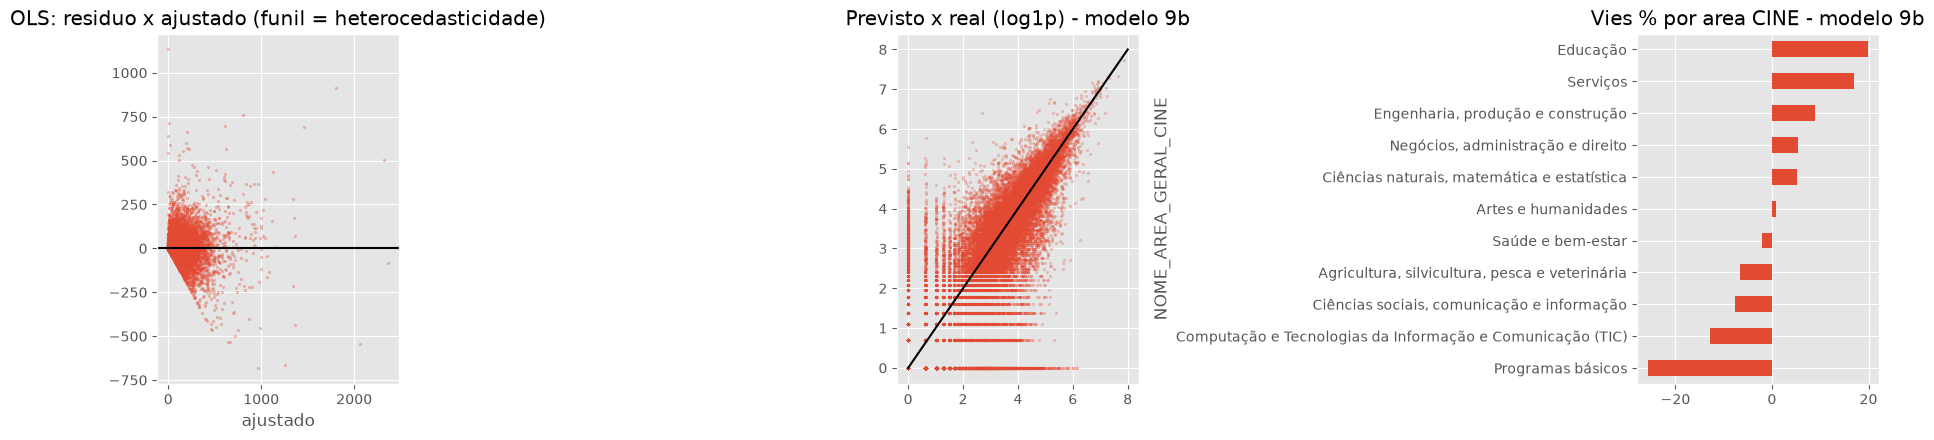

In [30]:
tr_d = p[p["T"] <= 2022]
Xd = sm.add_constant(tr_d[COMP])
ols_d = sm.OLS(tr_d["y_next_B"], Xd).fit(cov_type="cluster", cov_kwds={"groups": tr_d["CURSO_ID"]})
print(ols_d.summary().tables[1])
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
bp = het_breuschpagan(ols_d.resid, Xd)
print(f"Breusch-Pagan p-valor = {bp[1]:.3g}  (<0.05: heterocedasticidade -> usar erro-padrao robusto/cluster)")
print("VIF:", {c: round(variance_inflation_factor(Xd.values, i), 1) for i, c in enumerate(Xd.columns) if c != "const"})
glm = sm.GLM(tr_d["y_next_B"], Xd, family=sm.families.Poisson()).fit()
disp = (glm.resid_pearson ** 2).sum() / glm.df_resid
print(f"Poisson: dispersao de Pearson = {disp:.1f} (>>1: superdispersao -> usar Quasi-Poisson/NegBin para inferencia)")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
fit_ = ols_d.fittedvalues
ax[0].scatter(fit_, ols_d.resid, s=3, alpha=.3); ax[0].axhline(0, c="k")
ax[0].set_title("OLS: residuo x ajustado (funil = heterocedasticidade)"); ax[0].set_xlabel("ajustado")
best = PREDS[("9b OLS proporcional y(t+1)=b*y(t)", "B")]
ax[1].scatter(np.log1p(best["pred"]), np.log1p(best["real"]), s=3, alpha=.25)
ax[1].plot([0, 8], [0, 8], c="k"); ax[1].set_title("Previsto x real (log1p) - modelo 9b")
bias = best.assign(e=best["pred"] - best["real"]).groupby("NOME_AREA_GERAL_CINE").apply(
    lambda g: g["e"].sum() / g["real"].sum() * 100).sort_values()
bias.plot.barh(ax=ax[2]); ax[2].set_title("Vies % por area CINE - modelo 9b")
plt.tight_layout(); plt.show()

**4.17 Aplicação ao planejamento: Gap de Capacidade.** O indicador é definido como *vagas planejadas − demanda prevista*. A tabela ilustra o uso do modelo proporcional para estimar a demanda de 2024 por área de formação, tomando as vagas novas de 2023 como aproximação das vagas planejadas. O indicador é um sinal de apoio à decisão, não uma recomendação automática de redução de vagas. A versão completa, por instituição e com regra de decisão, está na seção 7.

In [31]:
b_prop = LinearRegression(fit_intercept=False).fit(p[p["T"] <= 2022][["y0"]], p[p["T"] <= 2022]["y_next_B"])
base24 = base[base["T"] == 2024].set_index("CURSO_ID")
gap = base[base["T"] == 2023].copy()
gap["DEMANDA_PREVISTA_2024"] = b_prop.predict(gap[[Y]].rename(columns={Y: "y0"}))
gap["VAGAS_NOVAS_2023"] = gap["QTD_VAGAS_NOVAS"]
gap["GAP"] = gap["VAGAS_NOVAS_2023"] - gap["DEMANDA_PREVISTA_2024"]
top = (gap.groupby("NOME_AREA_GERAL_CINE")[["VAGAS_NOVAS_2023", "DEMANDA_PREVISTA_2024", "GAP"]].sum()
       .assign(OCUPACAO_PREVISTA=lambda d: d["DEMANDA_PREVISTA_2024"] / d["VAGAS_NOVAS_2023"]).round(2))
display(top.sort_values("GAP", ascending=False))
print("(Exemplo ilustrativo: usa as vagas de 2023 como proxy das vagas planejadas de 2024.)")

,VAGAS_NOVAS_2023,DEMANDA_PREVISTA_2024,GAP,OCUPACAO_PREVISTA
NOME_AREA_GERAL_CINE,,,,
"Negócios, administração e direito",320987,77455.04,243531.96,0.24
"Engenharia, produção e construção",164056,23588.10,140467.90,0.14
Saúde e bem-estar,201185,69925.56,131259.44,0.35
Educação,78166,11465.20,66700.80,0.15
Computação e Tecnologias da Informação e Comunicação (TIC),89018,32354.27,56663.73,0.36
"Ciências sociais, comunicação e informação",80795,32765.33,48029.67,0.41
Artes e humanidades,42218,9545.44,32672.56,0.23
Serviços,25186,4066.91,21119.09,0.16
"Agricultura, silvicultura, pesca e veterinária",26525,10762.89,15762.11,0.41


(Exemplo ilustrativo: usa as vagas de 2023 como proxy das vagas planejadas de 2024.)


## 5. Análise preditiva – ensino a distância (EAD)

**Por que uma seção própria.** A modalidade EAD apresenta características distintas do presencial:

- **Crescimento acelerado:** os ingressantes em vagas novas aumentam várias vezes ao longo de 2015–2024, ao passo que o presencial encolhe.
- **Ausência de vagas e inscrições:** o Censo não registra essas informações para o EAD. Por isso, as variáveis de oferta usadas no presencial **não existem** aqui, e o indicador *Gap de Capacidade* não pode ser calculado com dados públicos.
- **Granularidade por polo:** cada linha representa um curso em um polo (município), o que gera muitas linhas por curso.

Em compensação, o EAD dispõe de variáveis que não estavam na base analítica do presencial, como **matrículas**, **evasão** (desvinculados e trancados) e **concluintes**.

O procedimento de avaliação é o mesmo da seção anterior (validação temporal expansiva e teste final em 2024), o que torna os resultados comparáveis.

**5.1 Exploração do EAD.** Apresentam-se: (i) a evolução do número de ingressantes, instituições e cursos; (ii) a razão *t+1 / t*, que indica a velocidade de crescimento do mercado; (iii) o percentual de cursos que deixam de existir de um ano para o outro; e (iv) a parcela dos ingressantes de *t+1* que vem de cursos **novos**, sem histórico. Esta última é importante porque nenhum modelo baseado em histórico consegue prever a demanda de um curso que ainda não existe.

,ingressantes_vagas_novas,matriculas,IES,cursos (IES x curso),crescimento_ingressantes
ANO,,,,,
2015,125916,257540,54,704,NaN
2016,172780,283082,64,810,0.372
2017,197304,320401,76,979,0.142
2018,237971,375411,112,1436,0.206
2019,276492,445017,141,2236,0.162
2020,379516,596312,164,3020,0.373
2021,498415,744282,200,3928,0.313
2022,604754,891550,230,4823,0.213
2023,686837,1053426,264,5577,0.136


,razao_t+1/t,cursos_que_fecham,ingressantes_de_cursos_novos_em_t+1
T,,,
2015,1.310,0.028,0.045
2016,1.031,0.028,0.097
2017,1.126,0.017,0.066
2018,1.021,0.021,0.121
2019,1.278,0.037,0.069
2020,1.205,0.038,0.082
2021,1.133,0.027,0.066
2022,1.087,0.030,0.043
2023,1.054,0.054,0.020


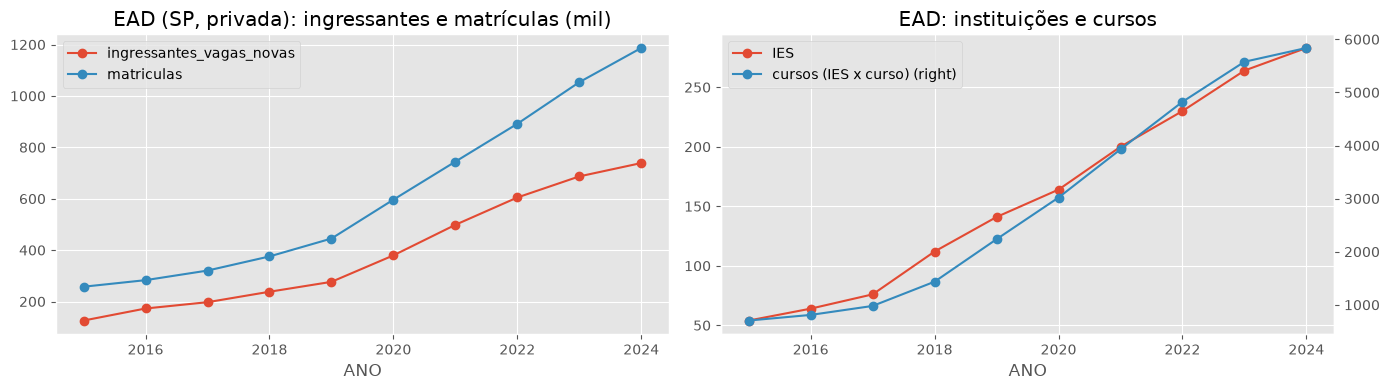

In [32]:
resumo_ead = pd.DataFrame({
    "ingressantes_vagas_novas": ead.groupby("ANO")["ING_NOVA"].sum(),
    "matriculas": ead.groupby("ANO")["MAT"].sum(),
    "IES": ead.groupby("ANO")["CO_IES"].nunique(),
    "cursos (IES x curso)": ead.groupby("ANO").apply(lambda g: g[["CO_IES", "CO_CURSO"]].drop_duplicates().shape[0]),
})
resumo_ead["crescimento_ingressantes"] = resumo_ead["ingressantes_vagas_novas"].pct_change().round(3)
display(resumo_ead)

tot_next = ead.groupby("ANO")["ING_NOVA"].sum().shift(-1)
de_existentes = p_curso.groupby("T")["y_nextB"].sum()
tab_novos = pd.DataFrame({
    "razao_t+1/t": (p_curso.groupby("T")["y_nextB"].sum() / p_curso.groupby("T")["y0"].sum()).round(3),
    "cursos_que_fecham": p_curso.groupby("T")["FECHOU"].mean().round(3),
    "ingressantes_de_cursos_novos_em_t+1": (1 - de_existentes / tot_next.reindex(de_existentes.index)).round(3),
})
display(tab_novos)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(resumo_ead[["ingressantes_vagas_novas", "matriculas"]] / 1e3).plot(ax=ax[0], marker="o")
ax[0].set_title("EAD (SP, privada): ingressantes e matrículas (mil)")
resumo_ead[["IES", "cursos (IES x curso)"]].plot(ax=ax[1], marker="o", secondary_y="cursos (IES x curso)")
ax[1].set_title("EAD: instituições e cursos")
plt.tight_layout(); plt.show()

**5.2 Avaliação das abordagens lineares no EAD.** As mesmas abordagens do presencial são comparadas, sem as variáveis de vagas e inscrições e com as de matrículas e evasão:

| Código | Modelo |
|---|---|
| 0a | Linha de base: ano seguinte = ano atual |
| 0b | Linha de base com crescimento: ano atual × razão observada no último ano de treino |
| 1 | OLS completo (todas as variáveis) |
| 2 | OLS proporcional: `y(t+1) = b · y(t)`, sem intercepto |
| 3 | OLS compacto (`y0`, `y1`, matrículas) |
| 4 | OLS em log com correção de Duan |
| 5 | Poisson |

A função `avaliar_ead` aplica a validação temporal expansiva (testes em 2019–2023) e o teste final em 2024 para cada nível de agregação.

In [33]:
def met_ead(y, p):
    e = p - y
    return dict(MAE=np.abs(e).mean(), WAPE=np.abs(e).sum() / y.sum(),
                VIES=e.sum() / y.sum() * 100, R2=1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum())


def avaliar_ead(painel, modelos, origens=(2018, 2019, 2020, 2021, 2022)):
    """Validação expansiva: treina com t<=T-1 e testa t=T; o teste final treina até 2022 e testa 2023 (alvo 2024)."""
    linhas = []
    for nome, fn in modelos.items():
        cv = []
        for T in origens:
            tr, te = painel[painel["T"] <= T - 1], painel[painel["T"] == T]
            cv.append(met_ead(te["y_nextB"].to_numpy(), np.clip(fn(tr, te), 0, None)))
        tr, te = painel[painel["T"] <= 2022], painel[painel["T"] == 2023]
        h = met_ead(te["y_nextB"].to_numpy(), np.clip(fn(tr, te), 0, None))
        m = pd.DataFrame(cv).mean()
        linhas.append(dict(modelo=nome, MAE=m.MAE, WAPE=m.WAPE, VIES=m.VIES, R2=m.R2,
                           WAPE_2024=h["WAPE"], MAE_2024=h["MAE"], VIES_2024=h["VIES"]))
    return pd.DataFrame(linhas).sort_values("WAPE").reset_index(drop=True)


def _xlog(d, cols):
    return np.log1p(d[cols].clip(lower=0))


def modelos_ead(F):
    def razao_ultimo_ano(tr, te):
        ult = tr[tr["T"] == tr["T"].max()]
        return te["y0"].to_numpy() * ult["y_nextB"].sum() / max(ult["y0"].sum(), 1)

    def ols_log(tr, te):
        m = LinearRegression().fit(_xlog(tr, F), np.log1p(tr["y_nextB"]))
        smear = np.exp(np.log1p(tr["y_nextB"]) - m.predict(_xlog(tr, F))).mean()
        return np.exp(m.predict(_xlog(te, F))) * smear - 1

    def poisson_ead(tr, te):
        sc = StandardScaler().fit(_xlog(tr, F))
        m = PoissonRegressor(alpha=1e-3, max_iter=1000).fit(sc.transform(_xlog(tr, F)), tr["y_nextB"])
        return m.predict(sc.transform(_xlog(te, F)))

    return {
        "0a Baseline y(t)": lambda tr, te: te["y0"].to_numpy(),
        "0b Baseline com razão do último ano": razao_ultimo_ano,
        "1 OLS completo": lambda tr, te: LinearRegression().fit(tr[F], tr["y_nextB"]).predict(te[F]),
        "2 OLS proporcional y(t+1)=b*y(t)": lambda tr, te: LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"]).predict(te[["y0"]]),
        "3 OLS compacto (y0, y1, matrículas)": lambda tr, te: LinearRegression().fit(tr[["y0", "y1", "mat0"]], tr["y_nextB"]).predict(te[["y0", "y1", "mat0"]]),
        "4 OLS log1p (Duan)": ols_log,
        "5 Poisson": poisson_ead,
    }


resultados_ead = {}
for nivel, pn, F in [("IES", p_ies, F_EAD),
                     ("IES x curso", p_curso, F_EAD),
                     ("IES x curso x polo", p_polo, [f for f in F_EAD if f != "npolos"])]:
    resultados_ead[nivel] = avaliar_ead(pn, modelos_ead(F))
    print(f"\n===== EAD – nível: {nivel} (linhas do painel: {len(pn):,}) =====")
    display(resultados_ead[nivel].round(3))


===== EAD – nível: IES (linhas do painel: 1,305) =====


,modelo,MAE,WAPE,VIES,R2,WAPE_2024,MAE_2024,VIES_2024
0,2 OLS proporcional y(t+1)=b*y(t),929.328,0.327,-6.491,0.748,0.186,518.108,-4.710
1,0b Baseline com razão do último ano,954.853,0.335,1.526,0.726,0.213,594.954,5.208
2,5 Poisson,970.035,0.340,-0.350,0.733,0.288,803.358,4.995
3,0a Baseline y(t),978.491,0.344,-18.007,0.769,0.187,520.958,-6.711
4,"3 OLS compacto (y0, y1, matrículas)",1018.790,0.359,-3.525,0.757,0.345,963.391,7.760
5,1 OLS completo,1281.262,0.446,-2.176,0.574,0.584,1629.961,13.329
6,4 OLS log1p (Duan),5664.999,1.969,186.234,-5.318,2.312,6446.874,229.404



===== EAD – nível: IES x curso (linhas do painel: 23,513) =====


,modelo,MAE,WAPE,VIES,R2,WAPE_2024,MAE_2024,VIES_2024
0,0a Baseline y(t),59.494,0.397,-12.119,0.741,0.271,35.190,-5.113
1,2 OLS proporcional y(t+1)=b*y(t),60.320,0.402,-8.713,0.732,0.274,35.626,-8.512
2,5 Poisson,62.954,0.419,1.181,0.726,0.334,43.338,4.418
3,0b Baseline com razão do último ano,63.018,0.420,1.356,0.691,0.286,37.140,3.184
4,"3 OLS compacto (y0, y1, matrículas)",67.138,0.448,-0.118,0.735,0.425,55.212,7.273
5,1 OLS completo,70.317,0.470,3.770,0.690,0.467,60.548,8.915
6,4 OLS log1p (Duan),114.641,0.758,55.475,0.056,0.643,83.480,51.935



===== EAD – nível: IES x curso x polo (linhas do painel: 487,607) =====


,modelo,MAE,WAPE,VIES,R2,WAPE_2024,MAE_2024,VIES_2024
0,2 OLS proporcional y(t+1)=b*y(t),4.120,0.614,-5.353,0.717,0.514,2.718,-6.063
1,0a Baseline y(t),4.152,0.619,-1.593,0.716,0.519,2.750,-0.158
2,0b Baseline com razão do último ano,4.244,0.632,0.305,0.706,0.521,2.757,0.387
3,5 Poisson,4.372,0.653,2.048,0.699,0.572,3.027,2.758
4,"3 OLS compacto (y0, y1, matrículas)",4.409,0.656,3.679,0.712,0.585,3.098,4.101
5,4 OLS log1p (Duan),4.466,0.667,-2.785,0.647,0.603,3.190,-8.125
6,1 OLS completo,4.523,0.676,3.564,0.694,0.612,3.241,4.781


**5.3 Variantes parcimoniosas do modelo proporcional.** Como os resultados anteriores indicam que a persistência do histórico explica quase toda a previsão, testam-se refinamentos que mantêm a equação simples:

- **novo/velho:** coeficientes separados para cursos com histórico e cursos novos (que tendem a crescer mais rápido);
- **por área CINE:** um coeficiente de crescimento para cada área de formação;
- **y0 e y1 sem intercepto:** acrescenta o ano anterior;
- **WLS:** ponderação que reduz a influência dos cursos muito grandes;
- **Huber:** regressão robusta a valores extremos;
- **com matrículas:** `y0` e matrículas, sem intercepto.

In [34]:
def lin_sem_intercepto(cols):
    return lambda tr, te: LinearRegression(fit_intercept=False).fit(tr[cols], tr["y_nextB"]).predict(te[cols])


def prop_por_area(tr, te):
    A = pd.get_dummies(pd.concat([tr["AREA"], te["AREA"]]), dtype=float)
    At, Ae = A.iloc[:len(tr)], A.iloc[len(tr):]
    m = LinearRegression(fit_intercept=False).fit(At.mul(tr["y0"].to_numpy(), axis=0), tr["y_nextB"])
    return m.predict(Ae.mul(te["y0"].to_numpy(), axis=0))


def wls_prop(tr, te):
    w = 1 / (1 + tr["y0"].to_numpy())
    return LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"], sample_weight=w).predict(te[["y0"]])


def huber_y0y1(tr, te):
    return HuberRegressor(fit_intercept=False, max_iter=500).fit(tr[["y0", "y1"]], tr["y_nextB"]).predict(te[["y0", "y1"]])


from sklearn.linear_model import HuberRegressor
variantes = {
    "0a Baseline y(t)": lambda tr, te: te["y0"].to_numpy(),
    "A proporcional y0": lin_sem_intercepto(["y0"]),
    "B proporcional novo/velho": lin_sem_intercepto(["y0_novo", "y0_velho"]),
    "C y0 e y1 sem intercepto": lin_sem_intercepto(["y0", "y1"]),
    "D y0 e matrículas sem intercepto": lin_sem_intercepto(["y0", "mat0"]),
    "F proporcional por área CINE": prop_por_area,
    "G WLS proporcional (peso 1/(1+y0))": wls_prop,
    "H Huber (y0, y1)": huber_y0y1,
}
variantes_ies = {k: v for k, v in variantes.items() if "área" not in k}
print("===== Variantes – IES x curso =====")
display(avaliar_ead(p_curso, variantes).round(3))
print("===== Variantes – IES =====")
display(avaliar_ead(p_ies, variantes_ies).round(3))

===== Variantes – IES x curso =====


,modelo,MAE,WAPE,VIES,R2,WAPE_2024,MAE_2024,VIES_2024
0,0a Baseline y(t),59.494,0.397,-12.119,0.741,0.271,35.190,-5.113
1,"H Huber (y0, y1)",59.567,0.397,-10.137,0.735,0.273,35.430,-3.320
2,C y0 e y1 sem intercepto,59.760,0.398,-9.280,0.733,0.286,37.125,-10.713
3,B proporcional novo/velho,60.209,0.402,-9.719,0.734,0.277,35.962,-8.736
4,A proporcional y0,60.320,0.402,-8.713,0.732,0.274,35.626,-8.512
5,F proporcional por área CINE,60.985,0.407,-5.949,0.721,0.279,36.178,-8.344
6,G WLS proporcional (peso 1/(1+y0)),61.559,0.410,-0.109,0.710,0.302,39.243,7.339
7,D y0 e matrículas sem intercepto,62.454,0.416,-10.690,0.729,0.301,39.094,-8.429


===== Variantes – IES =====


,modelo,MAE,WAPE,VIES,R2,WAPE_2024,MAE_2024,VIES_2024
0,G WLS proporcional (peso 1/(1+y0)),907.356,0.319,0.169,0.737,0.256,714.115,12.816
1,"H Huber (y0, y1)",911.976,0.320,-3.836,0.747,0.229,639.319,7.583
2,C y0 e y1 sem intercepto,920.905,0.324,-7.900,0.748,0.195,543.938,-7.955
3,A proporcional y0,929.328,0.327,-6.491,0.748,0.186,518.108,-4.710
4,B proporcional novo/velho,934.683,0.328,-8.517,0.752,0.186,518.489,-5.216
5,0a Baseline y(t),978.491,0.344,-18.007,0.769,0.187,520.958,-6.711
6,D y0 e matrículas sem intercepto,1021.326,0.360,-2.458,0.751,0.260,725.045,2.827


**5.4 Coeficientes e qualidade da previsão em 2024.** Ajusta-se o modelo proporcional com os dados até 2022 e interpreta-se o coeficiente: um valor próximo de 1 indica que o número de ingressantes de um curso tende a se repetir no ano seguinte; valores acima de 1, crescimento. Os gráficos comparam a previsão para 2024 com o valor observado, por instituição e por curso (escala logarítmica, em que a diagonal representa acerto perfeito).

Coeficiente do modelo proporcional (IES x curso): [0.964]
Coeficientes separados [curso novo, curso com histórico]: [1.268 0.948]


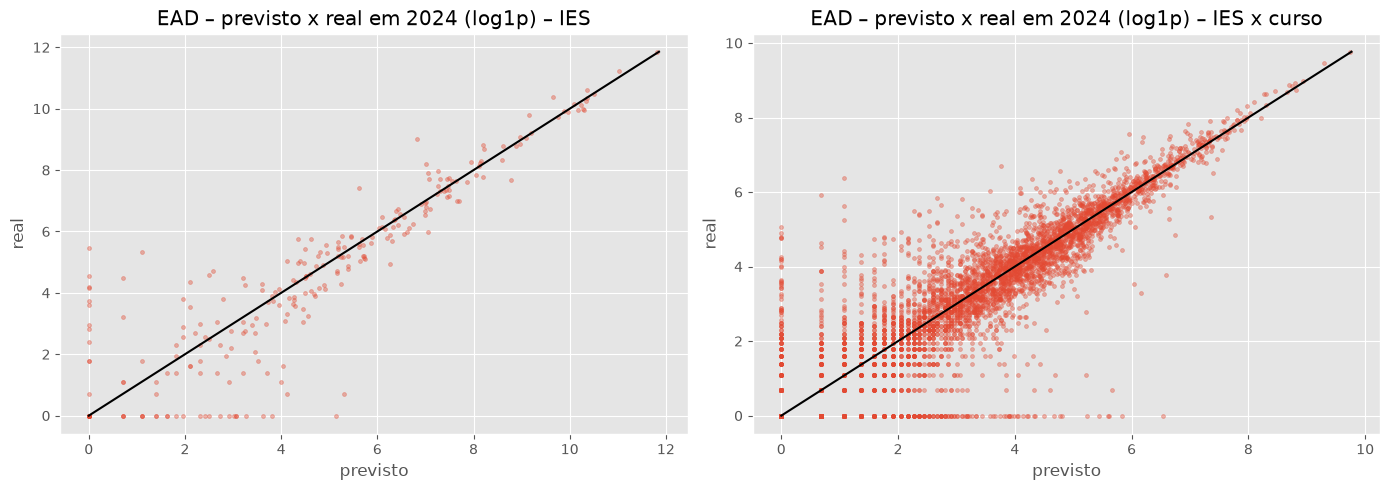

In [35]:
tr = p_curso[p_curso["T"] <= 2022]
m_prop = LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"])
m_nv = LinearRegression(fit_intercept=False).fit(tr[["y0_novo", "y0_velho"]], tr["y_nextB"])
print("Coeficiente do modelo proporcional (IES x curso):", m_prop.coef_.round(3))
print("Coeficientes separados [curso novo, curso com histórico]:", m_nv.coef_.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (nome, pn) in zip(ax, [("IES", p_ies), ("IES x curso", p_curso)]):
    tr_, te_ = pn[pn["T"] <= 2022], pn[pn["T"] == 2023]
    mod = LinearRegression(fit_intercept=False).fit(tr_[["y0"]], tr_["y_nextB"])
    prev = np.clip(mod.predict(te_[["y0"]]), 0, None)
    a.scatter(np.log1p(prev), np.log1p(te_["y_nextB"]), s=8, alpha=.4)
    lim = np.log1p(max(prev.max(), te_["y_nextB"].max()))
    a.plot([0, lim], [0, lim], c="k")
    a.set_title(f"EAD – previsto x real em 2024 (log1p) – {nome}")
    a.set_xlabel("previsto"); a.set_ylabel("real")
plt.tight_layout(); plt.show()

**5.5 Avaliação do total de mercado.** Para o planejamento estratégico, interessa também o total de ingressantes do EAD em SP. Compara-se o total previsto para 2024 (soma das previsões do modelo proporcional) com o total observado, para verificar se há viés sistemático de nível.

In [36]:
te = p_curso[p_curso["T"] == 2023]
prev_total = np.clip(m_prop.predict(te[["y0"]]), 0, None).sum()
real_total = te["y_nextB"].sum()
print(f"Ingressantes em vagas novas do EAD em 2024 (cursos existentes em 2023):")
print(f"  previsto: {prev_total:,.0f} | observado: {real_total:,.0f} | diferença: {(prev_total / real_total - 1) * 100:+.1f}%")
print(f"  baseline y(t): {te['y0'].sum():,.0f} ({(te['y0'].sum() / real_total - 1) * 100:+.1f}%)")

Ingressantes em vagas novas do EAD em 2024 (cursos existentes em 2023):
  previsto: 662,236 | observado: 723,850 | diferença: -8.5%
  baseline y(t): 686,837 (-5.1%)


## 6. Teste de sensibilidade: painel balanceado (cursos e instituições presentes nos 10 anos)

**Motivação.** Nem todas as instituições e cursos aparecem em todos os anos do Censo: alguns foram criados após 2015 e outros foram encerrados. Uma possibilidade seria restringir a análise apenas às entidades presentes nos 10 anos (2015–2024), formando um *painel balanceado*, no qual todas as séries têm o mesmo comprimento.

**Por que isso não foi adotado no modelo principal.** O filtro introduz o chamado **viés de sobrevivência**:

- ele mantém apenas as entidades que *existiram até o final*, informação que só seria conhecida no futuro; em uma previsão real, não se sabe em 2023 quais cursos ainda existirão em 2024;
- elimina justamente os cursos novos e os cursos que fecham, que fazem parte da realidade que a instituição precisa antecipar;
- no EAD, descartaria a maior parte do mercado, que foi construído depois de 2019.

**O que esta seção faz.** Em vez de decidir apenas por argumento, o filtro é testado e comparado com a base completa. Para cada nível de análise são apresentados: (i) quanto da base seria descartado; (ii) o erro do modelo na base completa e no painel balanceado; e (iii) o erro obtido ao **treinar apenas com as entidades de 10 anos e aplicar o modelo a todas**, que mostra se o filtro melhora o modelo para a população real.

**6.1 Cobertura do filtro.** Para cada nível de agregação, conta-se quantas entidades (cursos ou instituições) aparecem nos 10 anos e qual parcela dos ingressantes de 2024 elas representam. O ensino presencial já foi convertido ao mesmo formato do EAD na seção 3.1, o que permite reutilizar as mesmas funções de construção do painel e de avaliação.

In [37]:
NANOS = 10   # 2015 a 2024

# pres_base (presencial no formato do EAD) foi criado na seção 3.1
NIVEIS = [("Presencial – por curso", pres_base, ["CO_IES", "CO_CURSO", "CO_MUNICIPIO"]),
          ("Presencial – por IES", pres_base, ["CO_IES"]),
          ("EAD – por IES x curso", ead, ["CO_IES", "CO_CURSO"]),
          ("EAD – por IES", ead, ["CO_IES"])]


def indice(df_, keys):
    return pd.MultiIndex.from_frame(df_[keys]) if len(keys) > 1 else pd.Index(df_[keys[0]])


cobertura = []
for nome, base_, keys in NIVEIS:
    anos = base_.groupby(keys)["ANO"].nunique()
    completos = anos[anos == NANOS].index
    em_2024 = base_[base_["ANO"] == 2024]
    parcela = em_2024.loc[indice(em_2024, keys).isin(completos), "ING_NOVA"].sum() / em_2024["ING_NOVA"].sum()
    cobertura.append({"nível": nome, "entidades": len(anos), "presentes nos 10 anos": len(completos),
                      "% das entidades": round(len(completos) / len(anos) * 100, 1),
                      "% dos ingressantes de 2024": round(parcela * 100, 1)})
display(pd.DataFrame(cobertura))

,nível,entidades,presentes nos 10 anos,% das entidades,% dos ingressantes de 2024
0,Presencial – por curso,10174,3831,37.7,66.8
1,Presencial – por IES,655,311,47.5,95.1
2,EAD – por IES x curso,6539,579,8.9,37.5
3,EAD – por IES,322,42,13.0,71.6


**6.2 Desempenho com e sem o filtro.** Para cada nível, o modelo proporcional (`y(t+1) = b · y(t)`) e a linha de base são avaliados em três configurações:

1. **Base completa** (referência do modelo principal);
2. **Painel balanceado** (somente entidades presentes nos 10 anos);
3. **Treino no painel balanceado, teste na base completa** (o modelo aprende só com os sobreviventes, mas é cobrado sobre todos).

O erro é o WAPE: média da validação temporal em 2019–2023 e valor no teste final de 2024. O coeficiente `b` estimado em cada configuração também é exibido: se for parecido, o filtro não altera o comportamento aprendido.

In [38]:
def treina_balanceado_testa_todos(pn, pb):
    """Treina o modelo proporcional só com `pb` e testa em `pn` (base completa)."""
    cv = []
    for T in (2018, 2019, 2020, 2021, 2022):
        tr, te = pb[pb["T"] <= T - 1], pn[pn["T"] == T]
        m = LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"])
        cv.append(met_ead(te["y_nextB"].to_numpy(), np.clip(m.predict(te[["y0"]]), 0, None))["WAPE"])
    tr, te = pb[pb["T"] <= 2022], pn[pn["T"] == 2023]
    m = LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"])
    h = met_ead(te["y_nextB"].to_numpy(), np.clip(m.predict(te[["y0"]]), 0, None))["WAPE"]
    return np.mean(cv), h


modelos_sens = {
    "Baseline y(t)": lambda tr, te: te["y0"].to_numpy(),
    "Proporcional y(t+1)=b*y(t)": lambda tr, te: LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"]).predict(te[["y0"]]),
}

linhas = []
for nome, base_, keys in NIVEIS:
    anos = base_.groupby(keys)["ANO"].nunique()
    completos = anos[anos == NANOS].index
    pn = painel_ead(base_, keys)
    pb = pn[indice(pn, keys).isin(completos)]
    a, b = avaliar_ead(pn, modelos_sens).set_index("modelo"), avaliar_ead(pb, modelos_sens).set_index("modelo")
    cv_x, h_x = treina_balanceado_testa_todos(pn, pb)
    coef_todos = LinearRegression(fit_intercept=False).fit(pn[pn["T"] <= 2022][["y0"]], pn[pn["T"] <= 2022]["y_nextB"]).coef_[0]
    coef_bal = LinearRegression(fit_intercept=False).fit(pb[pb["T"] <= 2022][["y0"]], pb[pb["T"] <= 2022]["y_nextB"]).coef_[0]
    prop = "Proporcional y(t+1)=b*y(t)"
    linhas.append({"nível": nome,
                   "WAPE baseline (completa)": a.loc["Baseline y(t)", "WAPE"],
                   "WAPE baseline (balanceado)": b.loc["Baseline y(t)", "WAPE"],
                   "WAPE modelo (completa)": a.loc[prop, "WAPE"],
                   "WAPE modelo (balanceado)": b.loc[prop, "WAPE"],
                   "WAPE modelo (treino balanc. -> teste completa)": cv_x,
                   "WAPE 2024 (completa)": a.loc[prop, "WAPE_2024"],
                   "WAPE 2024 (balanceado)": b.loc[prop, "WAPE_2024"],
                   "WAPE 2024 (treino balanc. -> teste completa)": h_x,
                   "coeficiente b (completa)": coef_todos, "coeficiente b (balanceado)": coef_bal})
sens = pd.DataFrame(linhas).set_index("nível")
display(sens.round(3).T)

nível,Presencial – por curso,Presencial – por IES,EAD – por IES x curso,EAD – por IES
WAPE baseline (completa),0.478,0.336,0.397,0.344
WAPE baseline (balanceado),0.426,0.313,0.347,0.312
WAPE modelo (completa),0.452,0.343,0.402,0.327
WAPE modelo (balanceado),0.406,0.322,0.354,0.291
WAPE modelo (treino balanc. -> teste completa),0.455,0.343,0.402,0.327
WAPE 2024 (completa),0.289,0.159,0.274,0.186
WAPE 2024 (balanceado),0.258,0.148,0.143,0.121
WAPE 2024 (treino balanc. -> teste completa),0.285,0.158,0.275,0.186
coeficiente b (completa),0.875,0.895,0.964,1.021
coeficiente b (balanceado),0.893,0.895,0.960,1.018


**6.3 Interpretação do teste de sensibilidade.**

- **O filtro descarta grande parte da base.** No EAD, apenas 9% dos cursos (IES × curso) estão presentes nos 10 anos e representam 38% dos ingressantes de 2024; no presencial, por curso, são 38% dos cursos e 67% dos ingressantes. Em nível de instituição o filtro preserva mais volume (95% no presencial e 72% no EAD), mas ainda exclui instituições novas.
- **O erro "melhora" apenas porque o teste fica mais fácil.** Os sobreviventes são cursos maiores e mais estáveis. No EAD por IES × curso, o WAPE de 2024 cai de 0,27 para 0,14 no painel balanceado, mas isso reflete a seleção da amostra, e não um modelo melhor. Além disso, saber que o curso existe em 2024 usa informação do futuro: a parcela do erro causada por cursos que fecham simplesmente desaparece.
- **O modelo não muda com o filtro.** O coeficiente `b` é praticamente o mesmo nas duas configurações, e treinar só com as entidades de 10 anos e aplicar à base completa produz o **mesmo erro** de treinar com tudo (por exemplo, EAD por IES × curso: 0,275 contra 0,274 em 2024). Ou seja, o filtro não traz ganho para a população real.

**Decisão.** O modelo principal permanece treinado e avaliado na **base completa**, que representa o problema real de previsão. O painel balanceado fica como **análise de robustez**: confirma que o comportamento do modelo é estável e permite observar tendências sem o efeito da entrada e da saída de cursos.

## 7. Análise prescritiva: o que fazer?

A análise preditiva responde *quantos alunos devem ingressar*. A análise prescritiva transforma essa estimativa em **orientação para decisão**. Como os choques de mercado não são previsíveis pelo histórico (seções 3 e 4), a previsão é apresentada em **três cenários**, e não em um único número:

- **base:** previsão do modelo proporcional (`y(t+1) = b · y(t)`), com `b` estimado com todos os dados até 2023;
- **pessimista:** previsão base reduzida na proporção do **pior erro de total** que o modelo cometeu entre 2019 e 2024 (a menor razão entre ingressantes reais e previstos);
- **otimista:** previsão base ampliada na proporção do **melhor desempenho do mercado frente à previsão** nesse período (a maior razão entre reais e previstos).

Assim, a faixa não é arbitrária: representa o intervalo em que o total real efetivamente variou em torno da previsão do modelo nos anos já observados.

Os cenários são calculados no nível da **instituição**, o mais estável (seções 4 a 6), e aplicados aos ingressantes de 2024 para estimar 2025. Cursos que ainda não existem não entram na previsão, pois nenhum modelo baseado em histórico consegue antecipá-los.

**7.1 Cenários de demanda por instituição para 2025.** A função `cenarios_demanda` (i) refaz, para cada ano-alvo de 2019 a 2024, a previsão do modelo proporcional treinada apenas com o passado e calcula a razão entre o total real e o total previsto; (ii) ajusta o coeficiente `b` com todos os dados até 2023; (iii) define os três fatores de crescimento (base = `b`; pessimista = `b` × menor razão, limitada a 1; otimista = `b` × maior razão, limitada ao mínimo de 1), garantindo a ordem pessimista ≤ base ≤ otimista; e (iv) multiplica os fatores pelos ingressantes de 2024 de cada instituição. São exibidas as dez maiores instituições de cada modalidade e o total.

In [39]:
nomes_ies = df[["COD_IES", "NOME_IES"]].drop_duplicates("COD_IES").set_index("COD_IES")["NOME_IES"]


def cenarios_demanda(base, ano_ref=2024):
    """Demanda prevista (2025) por instituição em três cenários, a partir dos ingressantes de `ano_ref`."""
    pn = painel_ead(base, ["CO_IES"])
    # faixa histórica de erro do modelo no total: (ingressantes reais) / (ingressantes previstos), por ano-alvo
    razao = {}
    for T in range(2018, 2024):
        tr, te = pn[pn["T"] <= T - 1], pn[pn["T"] == T]
        m = LinearRegression(fit_intercept=False).fit(tr[["y0"]], tr["y_nextB"])
        razao[T + 1] = te["y_nextB"].sum() / m.predict(te[["y0"]]).sum()
    razao = pd.Series(razao)
    b = LinearRegression(fit_intercept=False).fit(pn[["y0"]], pn["y_nextB"]).coef_[0]
    fator = {"pessimista": b * min(razao.min(), 1), "base": b, "otimista": b * max(razao.max(), 1)}
    atual = base[base["ANO"] == ano_ref].groupby("CO_IES", as_index=False)["ING_NOVA"].sum().rename(
        columns={"ING_NOVA": "ingressantes_2024"})
    for nome, f in fator.items():
        atual[f"demanda_2025_{nome}"] = atual["ingressantes_2024"] * f
    return atual, fator, razao


cen = {}
for nome, base_ in [("EAD", ead), ("Presencial", pres_base)]:
    cen[nome], fator, razao = cenarios_demanda(base_)
    print(f"===== {nome} – fatores de crescimento 2024→2025: " + ", ".join(f"{k} {v:.3f}" for k, v in fator.items())
          + f" | razão real/previsto no total por ano-alvo: {razao.round(3).to_dict()}")
    topo = cen[nome].sort_values("ingressantes_2024", ascending=False).head(10).copy()
    topo.insert(1, "instituição", topo["CO_IES"].map(nomes_ies))
    total = cen[nome].drop(columns="CO_IES").sum()
    topo.loc["TOTAL", ["ingressantes_2024", "demanda_2025_pessimista", "demanda_2025_base", "demanda_2025_otimista"]] = total[
        ["ingressantes_2024", "demanda_2025_pessimista", "demanda_2025_base", "demanda_2025_otimista"]]
    display(topo.drop(columns="CO_IES").round(0))

===== EAD – fatores de crescimento 2024→2025: pessimista 0.991, base 1.034, otimista 1.259 | razão real/previsto no total por ano-alvo: {2019: 0.958, 2020: 1.217, 2021: 1.095, 2022: 0.998, 2023: 1.118, 2024: 1.049}


,instituição,ingressantes_2024,demanda_2025_pessimista,demanda_2025_base,demanda_2025_otimista
26,UNIVERSIDADE NORTE DO PARANÁ,140938.0,139692.0,145773.0,177404.0
88,CENTRO UNIVERSITÁRIO DE MARINGÁ - UNICESUMAR,74552.0,73893.0,77110.0,93842.0
29,UNIVERSIDADE PAULISTA,39926.0,39573.0,41296.0,50256.0
40,UNIVERSIDADE CIDADE DE SÃO PAULO,35317.0,35005.0,36529.0,44455.0
218,FACULDADE CAPITAL FEDERAL,32131.0,31847.0,33233.0,40445.0
94,CENTRO UNIVERSITÁRIO UNISEB,30818.0,30546.0,31875.0,38792.0
112,CENTRO UNIVERSITÁRIO INTERNACIONAL,28479.0,28227.0,29456.0,35848.0
16,UNIVERSIDADE CRUZEIRO DO SUL,25506.0,25281.0,26381.0,32105.0
27,UNIVERSIDADE NOVE DE JULHO,24807.0,24588.0,25658.0,31226.0
49,UNIVERSIDADE ANHEMBI MORUMBI,22105.0,21910.0,22863.0,27824.0


===== Presencial – fatores de crescimento 2024→2025: pessimista 0.598, base 0.897, otimista 1.250 | razão real/previsto no total por ano-alvo: {2019: 1.037, 2020: 0.871, 2021: 0.666, 2022: 1.393, 2023: 1.112, 2024: 1.107}


,instituição,ingressantes_2024,demanda_2025_pessimista,demanda_2025_base,demanda_2025_otimista
42,UNIVERSIDADE PAULISTA,37576.0,22460.0,33724.0,46985.0
40,UNIVERSIDADE NOVE DE JULHO,24503.0,14646.0,21991.0,30639.0
22,UNIVERSIDADE CRUZEIRO DO SUL,16532.0,9881.0,14837.0,20672.0
57,UNIVERSIDADE CIDADE DE SÃO PAULO,10481.0,6265.0,9406.0,13106.0
54,CENTRO UNIVERSITÁRIO ANHANGUERA DE SÃO PAULO,9305.0,5562.0,8351.0,11635.0
52,CENTRO UNIVERSITÁRIO DAS FACULDADES METROPOLIT...,8389.0,5014.0,7529.0,10490.0
16,UNIVERSIDADE SÃO JUDAS TADEU,7257.0,4338.0,6513.0,9074.0
66,UNIVERSIDADE ANHEMBI MORUMBI,5905.0,3529.0,5300.0,7384.0
1,UNIVERSIDADE PRESBITERIANA MACKENZIE,5742.0,3432.0,5153.0,7180.0
53,UNIVERSIDADE DE SANTO AMARO,5322.0,3181.0,4776.0,6655.0


**7.2 Gap de Capacidade e regra de decisão (presencial).** O *Gap de Capacidade* é a diferença entre as vagas planejadas e a demanda prevista. Como o Censo informa as vagas apenas do ensino presencial, a regra de decisão é aplicada a essa modalidade. Premissa: as vagas planejadas de 2025 são iguais às vagas novas de 2024; a variável `VAGAS_PLANEJADAS_2025` permite substituí-las por valores reais de cada instituição.

Para cada instituição calcula-se a **ocupação prevista** (demanda prevista ÷ vagas) em cada cenário e compara-se com a **ocupação média histórica da própria instituição** (2019–2024), pois a taxa de ocupação típica varia muito de uma instituição para outra. A recomendação segue a regra:

| Situação | Recomendação |
|---|---|
| Mesmo no cenário otimista, a ocupação prevista fica mais de 10% abaixo da média histórica | **Revisar a oferta** (ociosidade provável) |
| No cenário base a ocupação fica mais de 10% abaixo da média histórica, mas o cenário otimista não | **Atenção** (acompanhar a captação) |
| Caso contrário | **Manter** a oferta |

A regra é um sinal de apoio à decisão e deve ser combinada com informações acadêmicas, financeiras e estratégicas; não é uma recomendação automática de corte de vagas.

In [40]:
VAGAS_PLANEJADAS_2025 = {}   # opcional: {COD_IES: vagas planejadas para 2025}; vazio = usa as vagas de 2024

vagas_2024 = pres_df[pres_df["ANO_CENSO"] == 2024].groupby("COD_IES")["QTD_VAGAS_NOVAS"].sum()
hist = pres_df[pres_df["ANO_CENSO"].between(2019, 2024)].groupby("COD_IES")[["QTD_INGRESSANTES_VAGAS_NOVAS", "QTD_VAGAS_NOVAS"]].sum()
ocup_hist = (hist["QTD_INGRESSANTES_VAGAS_NOVAS"] / hist["QTD_VAGAS_NOVAS"].replace(0, np.nan)).rename("ocupação histórica")

gap = cen["Presencial"].set_index("CO_IES").join(vagas_2024.rename("vagas_2024")).join(ocup_hist)
gap["vagas_2025"] = [VAGAS_PLANEJADAS_2025.get(i, v) for i, v in zip(gap.index, gap["vagas_2024"])]
gap = gap[gap["vagas_2025"] > 0].dropna(subset=["ocupação histórica"]).copy()
for c in ["pessimista", "base", "otimista"]:
    gap[f"ocupação {c}"] = gap[f"demanda_2025_{c}"] / gap["vagas_2025"]
gap["gap_de_capacidade (base)"] = gap["vagas_2025"] - gap["demanda_2025_base"]


def regra(l):
    limite = 0.9 * l["ocupação histórica"]
    if l["ocupação otimista"] < limite:
        return "Revisar a oferta"
    if l["ocupação base"] < limite:
        return "Atenção"
    return "Manter"


gap["recomendação"] = gap.apply(regra, axis=1)
resumo_reg = gap.groupby("recomendação").agg(instituições=("vagas_2025", "size"), vagas_2025=("vagas_2025", "sum"),
                                              gap_base=("gap_de_capacidade (base)", "sum"))
resumo_reg["% das vagas"] = (resumo_reg["vagas_2025"] / resumo_reg["vagas_2025"].sum() * 100).round(1)
display(resumo_reg.round(0))

top_rev = gap[gap["recomendação"] != "Manter"].sort_values("gap_de_capacidade (base)", ascending=False).head(10).copy()
top_rev.insert(0, "instituição", top_rev.index.map(nomes_ies))
display(top_rev[["instituição", "vagas_2025", "demanda_2025_base", "gap_de_capacidade (base)",
                 "ocupação histórica", "ocupação base", "ocupação otimista", "recomendação"]].round(2))

,instituições,vagas_2025,gap_base,% das vagas
recomendação,,,,
Atenção,117,235896,174793.0,27.0
Manter,230,525065,321107.0,60.0
Revisar a oferta,82,118966,102583.0,14.0


,instituição,vagas_2025,demanda_2025_base,gap_de_capacidade (base),ocupação histórica,ocupação base,ocupação otimista,recomendação
CO_IES,,,,,,,,
316,UNIVERSIDADE NOVE DE JULHO,114521,21990.83,92530.17,0.24,0.19,0.27,Atenção
1294,FACULDADE DAS AMÉRICAS,32488,2356.77,30131.23,0.13,0.07,0.10,Revisar a oferta
374,CENTRO UNIVERSITÁRIO DAS FACULDADES METROPOLIT...,25026,7528.92,17497.08,0.47,0.30,0.42,Revisar a oferta
670,UNIVERSIDADE SÃO FRANCISCO,9369,3160.91,6208.09,0.50,0.34,0.47,Atenção
496,UNIVERSIDADE DE FRANCA,7382,2490.49,4891.51,0.38,0.34,0.47,Atenção
2556,FIAM-FAAM - CENTRO UNIVERSITÁRIO,5250,724.26,4525.74,0.38,0.14,0.19,Revisar a oferta
4169,FACULDADE NOSSA CIDADE,5232,886.71,4345.29,0.23,0.17,0.24,Atenção
952,UNIVERSIDADE SANTA CECÍLIA,5410,1709.69,3700.31,0.36,0.32,0.44,Atenção
1418,CENTRO UNIVERSITÁRIO TOLEDO,3252,296.17,2955.83,0.20,0.09,0.13,Revisar a oferta


**7.3 Planejamento de capacidade no EAD.** O Censo não registra as vagas do EAD (seção 2.7), portanto o Gap de Capacidade não pode ser calculado com dados públicos. Para a instituição, a recomendação é usar a demanda prevista nos três cenários (tabela 7.1) como referência de **dimensionamento em número de alunos** (tutores, turmas virtuais, polos e suporte) e comparar com a capacidade operacional interna. A variável `vagas_planejadas_ead` permite informar a oferta planejada de cada instituição e obter o mesmo gap e a mesma regra.

In [41]:
vagas_planejadas_ead = {}   # {COD_IES: vagas/capacidade planejada para 2025}; preencher com dados internos da instituição

if not vagas_planejadas_ead:
    print("Nenhuma capacidade planejada informada: o gap do EAD será calculado quando 'vagas_planejadas_ead' for preenchido.")
else:
    g = cen["EAD"].set_index("CO_IES").loc[list(vagas_planejadas_ead)].copy()
    g["capacidade_planejada"] = pd.Series(vagas_planejadas_ead)
    for c in ["pessimista", "base", "otimista"]:
        g[f"gap_{c}"] = g["capacidade_planejada"] - g[f"demanda_2025_{c}"]
    display(g.round(0))

Nenhuma capacidade planejada informada: o gap do EAD será calculado quando 'vagas_planejadas_ead' for preenchido.


**7.4 Conclusões da análise prescritiva.**

- **Faixa de demanda para 2025.** No EAD, o total previsto é de cerca de **764 mil ingressantes em vagas novas no cenário base** (+3,4% sobre 2024), com faixa de **732 mil (pessimista) a 930 mil (otimista)**. No presencial, o cenário base é de cerca de **281 mil** (−10% sobre 2024), com faixa de **187 mil a 392 mil**. A faixa do presencial é bem mais larga porque inclui o choque de 2021, o pior ano de erro do modelo (razão real/previsto de 0,67); no EAD, o modelo subestimou o crescimento na maior parte dos anos, de modo que a faixa é assimétrica para cima.
- **Ressalva sobre o cenário otimista do EAD.** O limite superior (+26%) é determinado principalmente por 2020, ano da pandemia, e deve ser lido como um teto histórico, não como uma expectativa. Nos dois anos mais recentes (2023 e 2024) o modelo subestimou o total em 5% a 12%, indicando que o cenário base pode estar ligeiramente conservador.
- **Regra de decisão (presencial).** Das 429 instituições com vagas informadas, **230 (60% das vagas)** são classificadas como *Manter*, **117 (27% das vagas)** como *Atenção* e **82 (14% das vagas)** como *Revisar a oferta*, isto é, instituições em que, mesmo no cenário otimista, a ocupação prevista fica mais de 10% abaixo da sua própria média histórica. A tabela lista as dez instituições com maior gap de capacidade entre as classificadas como *Atenção* ou *Revisar a oferta*.
- **EAD.** Sem vagas no Censo, a instituição deve usar a demanda prevista nos três cenários como referência de dimensionamento e comparar com a própria capacidade operacional (variável `vagas_planejadas_ead`).

**Limitações.** A previsão cobre apenas cursos e instituições que já existiam em 2024; no EAD, os cursos novos representam de 2% a 12% dos ingressantes de cada ano e não estão incluídos. No presencial, as vagas de 2025 foram supostas iguais às de 2024 (premissa substituível por dados reais), e o número de vagas novas do Censo é, em média, bem superior ao de ingressantes, de modo que o *gap* em valores absolutos deve ser validado com a instituição antes de ser usado em decisões.

## 8. Conclusões e recomendações

### 8.1 Ensino presencial

- A abordagem de melhor desempenho na validação temporal foi o **modelo linear proporcional** (`y(t+1) = b · y(t)`), com WAPE médio de **0,452** e viés de +2,9%. No teste final de 2024 o desempenho (WAPE 0,289) foi equivalente ao da linha de base "repetir o ano anterior" (0,286).
- OLS completo, OLS compacto e Poisson ficaram em patamar semelhante (WAPE de 0,469 a 0,473).
- **Modelos em escala logarítmica e com efeitos fixos de área, município e instituição apresentaram desempenho inferior** (WAPE entre 0,61 e 0,68, com viés de +35% a +45%). O log privilegia erros relativos em cursos pequenos e, após a reconversão, superestima os cursos grandes, que são justamente os mais relevantes para o planejamento.
- **Agregar não melhorou a previsão:** somar as previsões por curso equivale à linha de base no nível instituição e instituição × área; treinar diretamente com dados agregados foi pior.
- A maior parte do erro é explicada por **choques de mercado** (razão *t+1 / t* de 0,63 em 2020 e 1,19 em 2021), e não pela falta de variáveis do curso.

### 8.2 Ensino a distância

- O EAD **pode ser modelado**, mas sem vagas e inscrições: o Censo não as registra para a modalidade. Consequentemente, o Gap de Capacidade depende de dados de oferta da própria instituição (vagas autorizadas, turmas ou polos).
- O mercado apresenta forte crescimento (ingressantes em vagas novas de 126 mil em 2015 para 739 mil em 2024), com desaceleração recente (razão *t+1 / t* de 1,05 em 2023). Entre 2% e 12% dos ingressantes de cada ano vêm de cursos novos, que modelos baseados em histórico não conseguem antecipar.
- Como no presencial, a **persistência do histórico domina**: o modelo proporcional e a linha de base obtiveram resultados equivalentes, e a inclusão de matrículas, evasão e demais variáveis **não** reduziu o erro.
- No **total de mercado**, o modelo proporcional previu para 2024 cerca de 8,5% a menos do que o observado (a linha de base ficou 5,1% abaixo), o que mostra que o crescimento da modalidade não é capturado apenas pelo histórico e reforça o uso de cenários.
- A previsão é **mais precisa quanto maior o nível de agregação**: o erro é menor para a instituição como um todo (WAPE de cerca de 0,19 em 2024) do que para o curso (cerca de 0,27) e é elevado para o polo (cerca de 0,5). Prever por polo, portanto, não é recomendado.
- Em cursos novos, o coeficiente de crescimento (≈1,27) é superior ao de cursos com histórico (≈0,95), o que reflete o período de implantação.

### 8.3 Recomendação

1. Manter a **base completa** (todas as instituições e cursos, inclusive os que entram e saem ao longo do período) no modelo principal. O painel balanceado (somente entidades presentes nos 10 anos) foi testado na seção 6 e não melhora o modelo; seu uso fica restrito à análise de robustez, pois introduz viés de sobrevivência.
2. Adotar o **modelo linear proporcional** como modelo principal, por ser simples, interpretável, estável e competitivo, e usá-lo como referência para modelos mais complexos.
3. Apresentar a previsão sempre com **faixa de cenários** (otimista, base e pessimista), derivada da variação histórica da razão *t+1 / t*, pois os choques de mercado não são previsíveis a partir do histórico.
4. No EAD, trabalhar no nível **instituição** (e, em segundo plano, **curso**), e tratar separadamente a previsão de **cursos novos**.
5. Para o Gap de Capacidade, validar com a instituição o significado de "vaga nova" e obter a oferta planejada de fontes internas antes de usar o indicador em valores absolutos.
6. Aplicar a regra de decisão da seção 7 (*Manter*, *Atenção*, *Revisar a oferta*) como **sinal de apoio**, sempre combinada com informações acadêmicas e financeiras da instituição, e atualizar os cenários a cada novo Censo.

### 8.4 Limitações e próximos passos

- A série tem apenas dez pontos por curso, o que limita métodos clássicos de séries temporais.
- Mudanças estruturais (expansão do EAD, pandemia, alterações de política de financiamento) afetam a estabilidade dos coeficientes.
- Como complemento, recomenda-se comparar com modelos não lineares (Random Forest, XGBoost, CatBoost) e adotá-los apenas se superarem o modelo proporcional por margem clara.
- Para o EAD, recomenda-se incluir matrículas e evasão na visão analítica oficial do projeto e testar indicadores de mercado (por exemplo, crescimento do total de ingressantes) como variáveis exógenas.

### 8.5 Análise cognitiva: próximos passos

A camada cognitiva, na qual o sistema aprende continuamente e interage com o usuário em linguagem natural, **não foi implementada** neste trabalho, cujo escopo é a regressão linear sobre dados tabulares. Os desdobramentos naturais são:

1. **Retreinamento contínuo:** reajustar o modelo a cada novo Censo, com monitoramento do erro (WAPE) e alerta quando ele ultrapassar limites definidos.
2. **Modelos não lineares como benchmark:** Random Forest, XGBoost e CatBoost, adotados apenas se superarem o modelo proporcional por margem clara.
3. **Assistente em linguagem natural:** consulta às previsões e aos cenários por meio de perguntas, por exemplo, "qual a demanda prevista do curso X em 2025 no cenário pessimista?".
4. **Resumos automáticos:** geração de texto por instituição com a demanda prevista, a faixa de cenários e o risco de ociosidade.
5. **Variáveis externas:** renda, emprego, demografia e política de financiamento, para antecipar choques que o histórico, sozinho, não captura.